# 2. Imports and settings


In [3]:

!pip install factor_analyzer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=d3b5f7c2b34941e67586fa905fd15d5844e1d2df5fe832fac689f54d65612787
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [ ]:
from __future__ import annotations
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    brier_score_loss,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
    ParameterSampler
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None



from sklearn.decomposition import FactorAnalysis
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import (
    calculate_bartlett_sphericity,
    calculate_kmo,
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_STATE = 42
YEARS = [2020, 2021, 2022, 2023]
PREDICTION_YEAR = 2024

# Change only these paths/column names if they differ in your data.
CSV_PATH = "data/final_dataset.csv"
OUTPUT_DIR = Path("model")
ID_COL = "ID"
TARGET_COL = "Business_Status"       # 0 = active, 1 = closed at beginning of 2024
CLOSED_YEAR_COL = "Active_upto_year"      # Change to the exact name in your CSV
STUDY_START_YEAR = 2020

REVENUE_COLS = {year: f"Total_Revenue_{year}" for year in YEARS}
EXPENDITURE_COLS = {year: f"Total_expenditure_{year}" for year in YEARS}
STAFF_COLS = {year: f"Staff_total_{year}" for year in YEARS}

N_ITER = 20
CV_FOLDS = 5


# 3. Load and validate the data


In [5]:
def load_and_validate_data(csv_path: str | Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    annual_cols = (
        list(REVENUE_COLS.values())
        + list(EXPENDITURE_COLS.values())
        + list(STAFF_COLS.values())
    )
    required = [ID_COL, TARGET_COL, CLOSED_YEAR_COL] + annual_cols
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df = df.drop_duplicates().reset_index(drop=True)
    if df[ID_COL].isna().any():
        raise ValueError(f"{ID_COL} contains missing values.")
    if df[ID_COL].duplicated().any():
        duplicates = df.loc[df[ID_COL].duplicated(False), ID_COL].unique()[:10]
        raise ValueError(
            "The code expects one row per enterprise. Duplicate IDs include: "
            f"{duplicates.tolist()}"
        )

    target = pd.to_numeric(df[TARGET_COL], errors="coerce")
    if target.isna().any() or not set(target.unique()).issubset({0, 1}):
        raise ValueError(f"{TARGET_COL} must contain only 0 and 1, with no missing values.")
    df[TARGET_COL] = target.astype(int)

    df[CLOSED_YEAR_COL] = pd.to_numeric(df[CLOSED_YEAR_COL], errors="coerce")
    # Older closure years are allowed at the validation stage. Those records
    # are reported and removed from the modelling cohort below because they
    # closed before any predictor year was observed.
    invalid_closed_year = df[CLOSED_YEAR_COL].notna() & (
        (df[CLOSED_YEAR_COL] < 1900)
        | (df[CLOSED_YEAR_COL] > PREDICTION_YEAR)
    )
    if invalid_closed_year.any():
        bad = sorted(df.loc[invalid_closed_year, CLOSED_YEAR_COL].unique())
        raise ValueError(f"Unexpected closure years: {bad}")

    # Active firms should not have a closure year before the prediction date.
    inconsistent_active = (
        (df[TARGET_COL] == 0)
        & df[CLOSED_YEAR_COL].notna()
        & (df[CLOSED_YEAR_COL] < PREDICTION_YEAR)
    )
    if inconsistent_active.any():
        warnings.warn(
            f"{inconsistent_active.sum()} active firms have a closure year before "
            f"{PREDICTION_YEAR}. Check their coding."
        )

    # Convert annual inputs to numeric. Impossible negative values become missing.
    for col in annual_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        negative = df[col] < 0
        if negative.any():
            warnings.warn(f"{negative.sum()} negative values in {col} were set to missing.")
            df.loc[negative, col] = np.nan

    return df

In [6]:
def prepare_analysis_cohort(df: pd.DataFrame) -> pd.DataFrame:
    """Remove firms that closed before the predictor window began."""
    closed_before_window = (
        df[CLOSED_YEAR_COL].notna()
        & (df[CLOSED_YEAR_COL] < STUDY_START_YEAR)
    )
    excluded = df.loc[closed_before_window]
    if not excluded.empty:
        print(
            f"\nExcluding {len(excluded)} enterprise(s) that closed before "
            f"{STUDY_START_YEAR}; they have no valid pre-closure observations "
            "inside the predictor window."
        )
        print("Excluded closure years:")
        print(excluded[CLOSED_YEAR_COL].value_counts().sort_index())

    cohort = df.loc[~closed_before_window].copy().reset_index(drop=True)
    if cohort[TARGET_COL].nunique() < 2:
        raise ValueError(
            "After excluding pre-window closures, the analysis cohort does "
            "not contain both target classes."
        )
    return cohort

In [7]:
def print_data_summary(df: pd.DataFrame) -> None:
    annual_cols = (
        list(REVENUE_COLS.values())
        + list(EXPENDITURE_COLS.values())
        + list(STAFF_COLS.values())
    )
    print("Dataset shape:", df.shape)
    print("\nTarget distribution:")
    print(df[TARGET_COL].value_counts().sort_index())
    print("\nClosure-year distribution:")
    print(df[CLOSED_YEAR_COL].value_counts(dropna=False).sort_index())
    print("\nMissing percentage in annual inputs:")
    print((100 * df[annual_cols].isna().mean()).round(1).sort_values(ascending=False))


In [8]:
#This function selects one type of annual variable and arranges its yearly values into a simpler table.
def yearly_frame(
    df: pd.DataFrame,
    column_map: dict[int, str],
) -> pd.DataFrame:

    result = df[
        [column_map[year] for year in YEARS]
    ].copy()

    result.columns = YEARS

    return result.apply(
        pd.to_numeric,
        errors="coerce",
    )

In [9]:
def last_observed_df(
    frame: pd.DataFrame
) -> pd.Series:

    values = frame.to_numpy(dtype=float)

    latest_values = np.full(
        len(frame),
        np.nan,
        dtype=float,
    )

    for i, row in enumerate(values):
        observed_values = row[np.isfinite(row)]

        if observed_values.size > 0:
            latest_values[i] = observed_values[-1]

    return pd.Series(
        latest_values,
        index=frame.index,
    )

In [10]:
#This function calculates the direction and rate of change of a variable over time for each enterprise.
def trend_slope_df(
    frame: pd.DataFrame
) -> pd.Series:

    values = frame.to_numpy(dtype=float)

    years = np.asarray(
        YEARS,
        dtype=float,
    ).reshape(-1, 1)

    slopes = np.full(
        len(frame),
        np.nan,
        dtype=float,
    )

    for i, row in enumerate(values):
        observed = np.isfinite(row)

        if observed.sum() >= 2:
            model = LinearRegression()

            model.fit(
                years[observed],
                row[observed],
            )

            slopes[i] = model.coef_[0]

    return pd.Series(
        slopes,
        index=frame.index,
    )

In [11]:

#This function converts the original yearly variables into machine-learning features
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    # Arrange annual values from 2020 to 2023.
    revenue = yearly_frame(df, REVENUE_COLS)
    expenditure = yearly_frame(df, EXPENDITURE_COLS)
    staff = yearly_frame(df, STAFF_COLS)

    # Calculate annual profit and profit margin.
    profit = revenue - expenditure
    margin = profit.div(revenue.replace(0, np.nan))

    features = pd.DataFrame(index=df.index)

    # Revenue variables
    features["Revenue_latest"] = last_observed_df(revenue)
    features["Revenue_mean"] = revenue.mean(axis=1, skipna=True)
    features["Revenue_std"] = revenue.std(axis=1, skipna=True)

    # Expenditure variables
    features["Expenditure_latest"] = last_observed_df(expenditure)
    features["Expenditure_mean"] = expenditure.mean(axis=1, skipna=True)
    features["Expenditure_std"] = expenditure.std(axis=1, skipna=True)

    # Staffing variables
    features["Staff_latest"] = last_observed_df(staff)
    features["Staff_mean"] = staff.mean(axis=1, skipna=True)
    features["Staff_std"] = staff.std(axis=1, skipna=True)

    # Profit variables
    features["Profit_latest"] = last_observed_df(profit)
    features["Profit_mean"] = profit.mean(axis=1, skipna=True)
    features["Profit_std"] = profit.std(axis=1, skipna=True)

    # Profit-margin variables
    features["Profit_margin_latest"] = last_observed_df(margin)
    features["Profit_margin_mean"] = margin.mean(axis=1, skipna=True)

    # Temporal trend variables
    features["Revenue_trend"] = trend_slope_df(revenue)
    features["Expenditure_trend"] = trend_slope_df(expenditure)
    features["Staff_trend"] = trend_slope_df(staff)

    # Count loss-making years.
    # Missing profit values are excluded.
    loss_indicator = profit.lt(0).where(profit.notna())
    features["Loss_years"] = loss_indicator.sum(axis=1)

    # Replace undefined or infinite values with missing values.
    return features.replace([np.inf, -np.inf], np.nan)

# 5. Create one fair train/validation/test split


In [12]:
#This function divides the dataset into three separate groups
def make_splits(df: pd.DataFrame):
    train_val, test = train_test_split(
        df,
        test_size=0.20,
        stratify=df[TARGET_COL],
        random_state=RANDOM_STATE,
    )
    train, validation = train_test_split(
        train_val,
        test_size=0.25,  # 25% of 80% = 20% of the complete sample
        stratify=train_val[TARGET_COL],
        random_state=RANDOM_STATE + 1,
    )
    return (
        train.reset_index(drop=True),
        validation.reset_index(drop=True),
        test.reset_index(drop=True),
    )

In [13]:
def show_split_counts(train, validation, test):
    table = pd.DataFrame(
        {
            name: split[TARGET_COL].value_counts().sort_index()
            for name, split in {
                "train": train,
                "validation": validation,
                "test": test,
            }.items()
        }
    ).T
    table.columns = ["active_0", "closed_1"]
    table["total"] = table.sum(axis=1)
    print(table)


# 6. Models and imbalance strategies
Oversampling is inside the pipeline. Therefore, it is applied only to the
training portion of each cross-validation fold, never to validation or test.


In [14]:
def model_specifications(scale_pos_weight: float):
    """
    Define the four classification models and their hyperparameter
    search spaces.

    Class imbalance is handled using class weights only.
    """

    specifications = {}

    # ---------------------------------------------------------
    # 1. Logistic Regression
    # ---------------------------------------------------------
    specifications["Logistic Regression"] = (
        Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                (
                    "scaler",
                    StandardScaler(),
                ),
                (
                    "model",
                    LogisticRegression(
                        max_iter=5000,
                        class_weight="balanced",
                        random_state=RANDOM_STATE,
                        solver="lbfgs"
                    ),
                ),
            ]
        ),
        {
            "model__C": np.logspace(-3, 5, 12).tolist(),
        },
    )

    # ---------------------------------------------------------
    # 2. Random Forest
    # ---------------------------------------------------------
    specifications["Random Forest"] = (
        Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                (
                    "model",
                    RandomForestClassifier(
                        class_weight="balanced",
                        random_state=RANDOM_STATE,
                        n_jobs=-1,
                    ),
                ),
            ]
        ),
        {
            "model__n_estimators": [100, 200, 300],
            "model__max_depth": [None, 5, 10, 20],
            "model__min_samples_split": [2, 3, 4],
            "model__min_samples_leaf": [1, 2, 4]
        },
    )

    # ---------------------------------------------------------
    # 3. XGBoost
    # ---------------------------------------------------------
    specifications["XGBoost"] = (
        Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                (
                    "model",
                    XGBClassifier(
                        scale_pos_weight=scale_pos_weight,
                        random_state=RANDOM_STATE,
                        n_jobs=-1,
                    ),
                ),
            ]
        ),
        {
            "model__n_estimators": [100,200,300],
            "model__max_depth": [6,7,8],
            "model__learning_rate": [0.005, 0.01, 0.03, 0.05],
            "model__subsample": [0.2, 0.3, 0.4],
            "model__colsample_bytree": [0.5, 0.6, 0.65],
            "model__min_child_weight": [3.0,4.0,5.0],
        },
    )

    # ---------------------------------------------------------
    # 4. LightGBM
    # ---------------------------------------------------------
    specifications["LightGBM"] = (
        Pipeline(
            steps=[
                (
                    "imputer",
                    SimpleImputer(strategy="median"),
                ),
                (
                    "model",
                    LGBMClassifier(
                        class_weight="balanced",
                        random_state=RANDOM_STATE,
                        n_jobs=-1,
                        verbose=-1,
                    ),
                ),
            ]
        ),
        {
            "model__n_estimators": [200, 400, 600],
            "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
            "model__num_leaves": [15, 31, 63],
            "model__max_depth": [-1, 5, 10, 20],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__colsample_bytree": [0.7, 0.85, 1.0],
            "model__min_child_samples": [10, 20, 40]
        },
    )

    return specifications



In [15]:
def tune_models(
    X_train: pd.DataFrame,
    y_train: pd.Series,
):
    """
    Tune the four classification models using stratified
    cross-validation and macro-F1 score.
    """

    # Stratified cross-validation preserves the active/closed
    # class distribution in every fold.
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    # Calculate the XGBoost class-imbalance weight:
    #
    # number of active firms / number of closed firms
    #
    # Here:
    # 0 = active
    # 1 = closed
    active_count = int((y_train == 0).sum())
    closed_count = int((y_train == 1).sum())

    if closed_count == 0:
        raise ValueError(
            "The training set does not contain any closed enterprises."
        )

    scale_pos_weight = active_count / closed_count

    print("Active enterprises:", active_count)
    print("Closed enterprises:", closed_count)
    print(
        "XGBoost scale_pos_weight:",
        round(scale_pos_weight, 4),
    )

    specifications = model_specifications(
        scale_pos_weight=scale_pos_weight
    )

    results = {}

    for model_name, (pipeline, parameters) in specifications.items():
        print(f"\nTuning {model_name}")

        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=parameters,
            n_iter=N_ITER,
            scoring="f1_macro",
            cv=cv,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            refit=True,
            return_train_score=False,
            verbose=1,
        )

        search.fit(X_train, y_train)

        results[model_name] = search

        print(
            "Best cross-validation macro-F1:",
            round(search.best_score_, 4),
        )
        print("Best parameters:")
        print(search.best_params_)

    return results


# 7. Threshold selection and evaluation
The threshold is chosen on validation data only. The test set is evaluated
once after the model and threshold have been selected.


In [16]:
#This function selects the probability cutoff that gives the best macro-F1 score on the validation data.
def choose_threshold(y_true, p_closed):
    candidates = np.linspace(0.10, 0.90, 161)
    scores = [f1_score(y_true, p_closed >= t, average="macro") for t in candidates]
    return float(candidates[int(np.argmax(scores))])

In [17]:
def evaluate_predictions(y_true, p_closed, threshold):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = (np.asarray(p_closed) >= threshold).astype(int)
    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "closed_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "closed_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "closed_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_true, p_closed),
        "pr_auc": average_precision_score(y_true, p_closed),
        "brier_score": brier_score_loss(y_true, p_closed),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1]),
        "classification_report": classification_report(y_true, y_pred, target_names=["Active", "Closed"], digits=4)
    }

In [18]:
#This function compares the four tuned models using the separate validation dataset.
def compare_on_validation(searches, X_validation, y_validation):
    rows = []
    for name, search in searches.items():
        p_closed = search.best_estimator_.predict_proba(X_validation)[:, 1]
        threshold = choose_threshold(y_validation, p_closed)
        metrics = evaluate_predictions(y_validation, p_closed, threshold)
        rows.append(
            {
                "model": name,
                "cv_macro_f1": search.best_score_,
                **metrics,
            }
        )
    return pd.DataFrame(rows).sort_values(
        ["macro_f1", "balanced_accuracy", "brier_score"],
        ascending=[False, False, True],
    ).reset_index(drop=True)

In [19]:
#This function evaluates the selected model on the final test dataset.
def final_test_evaluation(model, threshold, X_test, y_test):
    p_closed = model.predict_proba(X_test)[:, 1]
    metrics = evaluate_predictions(y_test, p_closed, threshold)
    predictions = (p_closed >= threshold).astype(int)

    print("Test metrics:")
    print(pd.Series(metrics).round(4))
    print("\nConfusion matrix [rows: actual, columns: predicted]:")
    print(confusion_matrix(y_test, predictions, labels=[0, 1]))
    print("\nClassification report:")
    print(classification_report(y_test, predictions, target_names=["Active", "Closed"], digits=4))
    return metrics, p_closed, predictions


In [20]:
def plot_calibration(y_true, p_closed, output_path=None):
    observed, predicted = calibration_curve(y_true, p_closed, n_bins=8, strategy="quantile")
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
    ax.plot(predicted, observed, marker="o", label="Selected model")
    ax.set(xlabel="Mean predicted closure probability", ylabel="Observed closure proportion")
    ax.set_title("Test-set calibration plot")
    ax.legend()
    fig.tight_layout()
    if output_path:
        fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()


# 8. Run Phase 1


In [21]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

raw_df = load_and_validate_data(CSV_PATH)
print_data_summary(raw_df)

analysis_df = prepare_analysis_cohort(raw_df)
print("\nAnalysis cohort shape:", analysis_df.shape)

train_df, validation_df, test_df = make_splits(analysis_df)
show_split_counts(train_df, validation_df, test_df)

Dataset shape: (759, 121)

Target distribution:
Business_Status
0    591
1    168
Name: count, dtype: int64

Closure-year distribution:
Active_upto_year
2010.0      1
2019.0      7
2020.0     32
2021.0     40
2022.0     50
2023.0     17
2024.0    603
NaN         9
Name: count, dtype: int64

Missing percentage in annual inputs:
Total_Revenue_2020        0.0
Total_Revenue_2021        0.0
Total_Revenue_2022        0.0
Total_Revenue_2023        0.0
Total_expenditure_2020    0.0
Total_expenditure_2021    0.0
Total_expenditure_2022    0.0
Total_expenditure_2023    0.0
Staff_total_2020          0.0
Staff_total_2021          0.0
Staff_total_2022          0.0
Staff_total_2023          0.0
dtype: float64

Excluding 8 enterprise(s) that closed before 2020; they have no valid pre-closure observations inside the predictor window.
Excluded closure years:
Active_upto_year
2010.0    1
2019.0    7
Name: count, dtype: int64

Analysis cohort shape: (751, 121)
            active_0  closed_1  total
train  

In [22]:
X_train = build_features(train_df)
y_train = train_df[TARGET_COL]
X_validation = build_features(validation_df)
y_validation = validation_df[TARGET_COL]
X_test = build_features(test_df)
y_test = test_df[TARGET_COL]

print("\nFeature matrix shapes:", X_train.shape, X_validation.shape, X_test.shape)
print("Features:", X_train.columns.tolist())


Feature matrix shapes: (450, 18) (150, 18) (151, 18)
Features: ['Revenue_latest', 'Revenue_mean', 'Revenue_std', 'Expenditure_latest', 'Expenditure_mean', 'Expenditure_std', 'Staff_latest', 'Staff_mean', 'Staff_std', 'Profit_latest', 'Profit_mean', 'Profit_std', 'Profit_margin_latest', 'Profit_margin_mean', 'Revenue_trend', 'Expenditure_trend', 'Staff_trend', 'Loss_years']


In [23]:
searches = tune_models(X_train, y_train)


Active enterprises: 354
Closed enterprises: 96
XGBoost scale_pos_weight: 3.6875

Tuning Logistic Regression
Fitting 5 folds for each of 12 candidates, totalling 60 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 12 is smaller than n_iter=20. Running 12 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best cross-validation macro-F1: 0.8534
Best parameters:
{'model__C': 18738.174228603868}

Tuning Random Forest
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best cross-validation macro-F1: 0.9244
Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_depth': 5}

Tuning XGBoost
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best cross-validation macro-F1: 0.9237
Best parameters:
{'model__subsample': 0.4, 'model__n_estimators': 200, 'model__min_child_weight': 4.0, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.6}

Tuning LightGBM
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best cross-validation macro-F1: 0.9216
Best parameters:
{'model__subsample': 0.7, 'model__num_leaves': 63, 'model__n_estimators': 400, 'model__min_child_samples': 20, 'model__max_depth': 10, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}


In [24]:
validation_comparison = compare_on_validation(searches, X_validation, y_validation)
print("\nValidation comparison:")
display(validation_comparison.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Validation comparison:


,model,cv_macro_f1,threshold,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,closed_precision,closed_recall,closed_f1,roc_auc,pr_auc,brier_score,confusion_matrix,classification_report
0,XGBoost,0.9237,0.670,0.9667,0.9447,0.9551,0.9447,0.9498,0.9355,0.9062,0.9206,0.9878,0.9632,0.0442,"[[116, 2], [3, 29]]",precision recall f1-score ...
1,Random Forest,0.9244,0.560,0.9600,0.9404,0.9404,0.9404,0.9404,0.9062,0.9062,0.9062,0.9836,0.9491,0.0487,"[[115, 3], [3, 29]]",precision recall f1-score ...
2,LightGBM,0.9216,0.370,0.9400,0.9277,0.9012,0.9277,0.9135,0.8286,0.9062,0.8657,0.9854,0.9587,0.0555,"[[112, 6], [3, 29]]",precision recall f1-score ...
3,Logistic Regression,0.8534,0.615,0.9267,0.9192,0.8786,0.9192,0.8965,0.7838,0.9062,0.8406,0.9470,0.8330,0.0981,"[[110, 8], [3, 29]]",precision recall f1-score ...


In [25]:
best_name = validation_comparison.loc[0, "model"]
best_threshold = float(validation_comparison.loc[0, "threshold"])
best_model = searches[best_name].best_estimator_

print("Selected model:", best_name)
print("Selected validation threshold:", round(best_threshold, 4))
print("Best hyperparameters:", searches[best_name].best_params_)

Selected model: XGBoost
Selected validation threshold: 0.67
Best hyperparameters: {'model__subsample': 0.4, 'model__n_estimators': 200, 'model__min_child_weight': 4.0, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.6}


Test metrics:
threshold                                                             0.67
accuracy                                                          0.953642
balanced_accuracy                                                 0.924895
macro_precision                                                   0.934946
macro_recall                                                      0.924895
macro_f1                                                            0.9298
closed_precision                                                  0.903226
closed_recall                                                        0.875
closed_f1                                                         0.888889
roc_auc                                                           0.911239
pr_auc                                                              0.9024
brier_score                                                       0.053019
confusion_matrix                                       [[116, 3], [4, 28]]
classificat

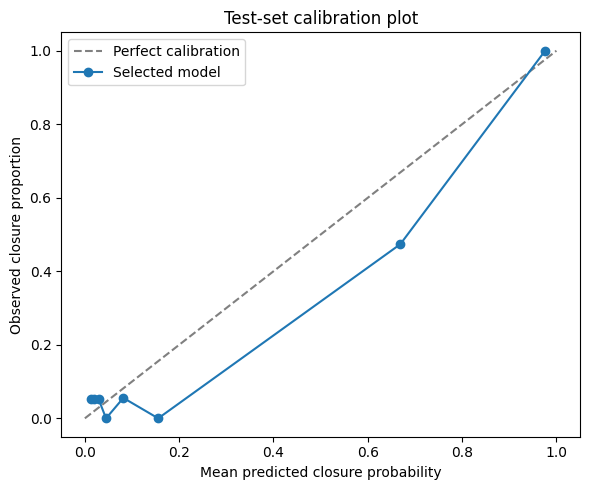

In [26]:
test_metrics, p_closed_test, y_pred_test = final_test_evaluation(
    best_model, best_threshold, X_test, y_test
)
plot_calibration(
    y_test,
    p_closed_test,
    OUTPUT_DIR / "phase1_test_calibration.png",
)


# 9. Save results and the evaluation model


In [27]:
validation_comparison.to_csv(OUTPUT_DIR / "phase1_validation_comparison.csv", index=False)
pd.DataFrame([{"model": best_name, **test_metrics}]).to_csv(
    OUTPUT_DIR / "phase1_test_metrics.csv", index=False
)

test_predictions = test_df[[ID_COL, TARGET_COL]].copy()
test_predictions["predicted_closed_probability"] = p_closed_test
test_predictions["predicted_status"] = y_pred_test
test_predictions.to_csv(OUTPUT_DIR / "phase1_test_predictions.csv", index=False)

joblib.dump(best_model, OUTPUT_DIR / "phase1_evaluation_model.joblib")
with open(OUTPUT_DIR / "phase1_metadata.json", "w") as file:
    json.dump(
        {
            "prediction_year": PREDICTION_YEAR,
            "model": best_name,
            "threshold": best_threshold,
            "features": X_train.columns.tolist(),
            "best_parameters": searches[best_name].best_params_,
            "random_state": RANDOM_STATE,
        },
        file,
        indent=2,
        default=str,
    )

print("Saved outputs to:", OUTPUT_DIR)


Saved outputs to: /content/drive/MyDrive/MSME_data/phase1_revised_outputs


# 10. Repeated out-of-fold Phase 1 probability targets for Phase 2
Phase 2 is a surrogate model: it learns the active probability produced by
Phase 1. Its regression metrics measure fidelity to Phase 1, not direct
business-closure performance. Repeated out-of-fold predictions are averaged
for the training target to reduce dependence on one CV partition.

In [28]:
OOF_REPEATS = 3
phase1_oof_active_repeats = np.zeros((len(X_train), OOF_REPEATS), dtype=float)

for repeat in range(OOF_REPEATS):
    repeat_cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE + 100 + repeat,
    )

    repeat_probabilities = np.full(len(X_train), np.nan, dtype=float)

    for fold_train_idx, fold_valid_idx in repeat_cv.split(X_train, y_train):
        fold_model = clone(best_model)
        fold_model.fit(
            X_train.iloc[fold_train_idx],
            y_train.iloc[fold_train_idx],
        )
        repeat_probabilities[fold_valid_idx] = fold_model.predict_proba(
            X_train.iloc[fold_valid_idx]
        )[:, 0]

    if np.isnan(repeat_probabilities).any():
        raise RuntimeError("Incomplete Phase 1 out-of-fold predictions.")

    phase1_oof_active_repeats[:, repeat] = repeat_probabilities

phase1_active_probability_train = phase1_oof_active_repeats.mean(axis=1)
phase1_active_probability_validation = best_model.predict_proba(X_validation)[:, 0]
phase1_active_probability_test = best_model.predict_proba(X_test)[:, 0]

PROBABILITY_COL = "Phase1_active_probability"
train_df[PROBABILITY_COL] = phase1_active_probability_train
validation_df[PROBABILITY_COL] = phase1_active_probability_validation
test_df[PROBABILITY_COL] = phase1_active_probability_test

train_df.to_csv(OUTPUT_DIR / "train_with_phase1_probability.csv", index=False)
validation_df.to_csv(OUTPUT_DIR / "validation_with_phase1_probability.csv", index=False)
test_df.to_csv(OUTPUT_DIR / "test_with_phase1_probability.csv", index=False)

print("Repeated OOF Phase 1 targets created for Phase 2.")
display(train_df[[ID_COL, TARGET_COL, PROBABILITY_COL]].head())


Repeated OOF Phase 1 targets created for Phase 2.


,ID,Business_Status,Phase1_active_probability
0,Micro-533,0,0.878115
1,Micro-343,0,0.884297
2,Micro-176,0,0.917478
3,Micro-8,0,0.847239
4,14-Mi,1,0.007621


# Phase 2

In [29]:
train_df.shape

(450, 122)

In [30]:
DROP_FROM_PHASE2 = [
    TARGET_COL,
    "Unnamed: 0",
    "Open_Year",
    "Active_upto_year",
    "Total_Revenue_2020",
    "Total_Revenue_2021",
    "Total_Revenue_2022",
    "Total_Revenue_2023",
    "Total_expenditure_2020",
    "Total_expenditure_2021",
    "Total_expenditure_2022",
    "Total_expenditure_2023",
    "Staff_total_2020",
    "Staff_total_2021",
    "Staff_total_2022",
    "Staff_total_2023",
]

train_phase2_df = train_df.drop(
    columns=DROP_FROM_PHASE2,
    errors="ignore",
).copy()

validation_phase2_df = validation_df.drop(
    columns=DROP_FROM_PHASE2,
    errors="ignore",
).copy()

test_phase2_df = test_df.drop(
    columns=DROP_FROM_PHASE2,
    errors="ignore",
).copy()

print("Phase 2 shapes:")
print("Train:", train_phase2_df.shape)
print("Validation:", validation_phase2_df.shape)
print("Test:", test_phase2_df.shape)

print("\nRemaining columns:")
print(train_phase2_df.columns.tolist())

Phase 2 shapes:
Train: (450, 106)
Validation: (150, 106)
Test: (151, 106)

Remaining columns:
['ID', 'Owner_age', 'Owner_gender', 'Owner_family_size', 'Main_Income_Source_Other', 'Main_Income_Source_MSME', 'Main_Income_Source_Non_Agriculture', 'Main_Income_Source_PVT_Sector', 'Main_Income_Source_Government', 'Business_Sole_Ownership', 'District_Kandy', 'District_Matale', 'District_NuwaraEliya', 'Owners_2020', 'Owners_2021', 'Owners_2022', 'Owners_2023', 'Admin_Staff_2020', 'Admin_Staff_2021', 'Admin_Staff_2022', 'Admin_Staff_2023', 'Tech_Staff_2020', 'Tech_Staff_2021', 'Tech_Staff_2022', 'Tech_Staff_2023', 'Employee_compensation_2020', 'Employee_compensation_2021', 'Employee_compensation_2022', 'Employee_compensation_2023', 'Cost_of_raw_materials_2020', 'Cost_of_raw_materials_2021', 'Cost_of_raw_materials_2022', 'Cost_of_raw_materials_2023', 'Utility_bills_2020', 'Utility_bills_2021', 'Utility_bills_2022', 'Utility_bills_2023', 'Finance_Cost_2020', 'Finance_Cost_2021', 'Finance_Cost_20

In [31]:
PHASE2_TARGET_COL = "Phase1_active_probability"

PHASE1_RAW_COLUMNS = [
    *[f"Total_Revenue_{year}" for year in YEARS],
    *[f"Total_expenditure_{year}" for year in YEARS],
    *[f"Staff_total_{year}" for year in YEARS],
]

EXCLUDED_COLUMNS = [
    "Unnamed: 0",
    ID_COL,
    TARGET_COL,
    CLOSED_YEAR_COL,
    *PHASE1_RAW_COLUMNS,
]

CONTINUOUS_GROUPS = {
    "owner_resources": [
        "Owner_age",
        "Owner_family_size",
        "Revenue_percent_withdrawn",
        "Owned_total_asset_market_value",
        "Rented_total_asset_market_value",
    ],
    "staffing": [
        *[f"Owners_{year}" for year in YEARS],
        *[f"Admin_Staff_{year}" for year in YEARS],
        *[f"Tech_Staff_{year}" for year in YEARS],
    ],
    "operating_costs": [
        *[f"Employee_compensation_{year}" for year in YEARS],
        *[f"Cost_of_raw_materials_{year}" for year in YEARS],
        *[f"Utility_bills_{year}" for year in YEARS],
        *[f"Finance_Cost_{year}" for year in YEARS],
        *[f"Rent_{year}" for year in YEARS],
        *[f"Transport_cost_{year}" for year in YEARS],
        *[f"Maintenance_cost_{year}" for year in YEARS],
        *[f"Other_expenses_{year}" for year in YEARS],
    ],
    "business_performance": [
        *[f"Gross_annual_revenue_{year}" for year in YEARS],
        "Minimum_2023_Monthly_profit",
        "Maximum_2023_Monthly_profit",
        *[f"Other_income_total_{year}" for year in YEARS],
    ],
    "investment_and_debt": [
        *[f"Cash_inflow_investing_{year}" for year in YEARS],
        *[f"Cash_inflow_financial_activities_{year}" for year in YEARS],
        *[f"total_investment_{year}" for year in YEARS],
        *[f"non-performing_debt_{year}" for year in YEARS],
    ],
}

CATEGORICAL_COLUMNS = [
    "Owner_gender",
    "Main_Income_Source_Other",
    "Main_Income_Source_MSME",
    "Main_Income_Source_Non_Agriculture",
    "Main_Income_Source_PVT_Sector",
    "Main_Income_Source_Government",
    "Business_Sole_Ownership",
    "District_Kandy",
    "District_Matale",
    "District_NuwaraEliya",
    "Raw_material_access_Local",
    "Raw_material_access_Regional",
    "Raw_material_access_National",
    "Raw_material_access_International",
    "Deposit_daily",
    "Deposit_weekly",
    "Deposit_monthly",
    "Withdraw_daily",
    "Withdraw_weekly",
    "Withdraw_monthly",
    "daily_recording",
    "annual_recording",
    "formal_sector_concessionary_loans",
    "foraml_sector_bank_loans",
    "formal_sector_other_loans",
    "formal_sector_micro_finance",
    "Informal_sector_informal_money",
    "Informal_sector_micro_finance",
    "Informal_sector_other_loans",
]

CONTINUOUS_COLUMNS = [
    column
    for group_columns in CONTINUOUS_GROUPS.values()
    for column in group_columns
]

APPROVED_PHASE2_COLUMNS = CONTINUOUS_COLUMNS + CATEGORICAL_COLUMNS
APPROVED_PHASE2_COLUMNS

['Owner_age',
 'Owner_family_size',
 'Revenue_percent_withdrawn',
 'Owned_total_asset_market_value',
 'Rented_total_asset_market_value',
 'Owners_2020',
 'Owners_2021',
 'Owners_2022',
 'Owners_2023',
 'Admin_Staff_2020',
 'Admin_Staff_2021',
 'Admin_Staff_2022',
 'Admin_Staff_2023',
 'Tech_Staff_2020',
 'Tech_Staff_2021',
 'Tech_Staff_2022',
 'Tech_Staff_2023',
 'Employee_compensation_2020',
 'Employee_compensation_2021',
 'Employee_compensation_2022',
 'Employee_compensation_2023',
 'Cost_of_raw_materials_2020',
 'Cost_of_raw_materials_2021',
 'Cost_of_raw_materials_2022',
 'Cost_of_raw_materials_2023',
 'Utility_bills_2020',
 'Utility_bills_2021',
 'Utility_bills_2022',
 'Utility_bills_2023',
 'Finance_Cost_2020',
 'Finance_Cost_2021',
 'Finance_Cost_2022',
 'Finance_Cost_2023',
 'Rent_2020',
 'Rent_2021',
 'Rent_2022',
 'Rent_2023',
 'Transport_cost_2020',
 'Transport_cost_2021',
 'Transport_cost_2022',
 'Transport_cost_2023',
 'Maintenance_cost_2020',
 'Maintenance_cost_2021',
 'M

In [32]:
def validate_phase2_schema(df: pd.DataFrame) -> None:
    required = [
        PHASE2_TARGET_COL,
        *APPROVED_PHASE2_COLUMNS,
    ]

    missing = sorted(set(required) - set(df.columns))

    if missing:
        raise ValueError(
            f"Missing required Phase 2 columns: {missing}"
        )

    duplicates = (
        pd.Index(APPROVED_PHASE2_COLUMNS)
        [pd.Index(APPROVED_PHASE2_COLUMNS).duplicated()]
        .unique()
        .tolist()
    )

    if duplicates:
        raise ValueError(
            f"Variables assigned more than once: {duplicates}"
        )

    overlap = set(CONTINUOUS_COLUMNS) & set(CATEGORICAL_COLUMNS)

    if overlap:
        raise ValueError(
            f"Continuous and categorical lists overlap: {sorted(overlap)}"
        )

    # Check continuous variables
    non_numeric_continuous = []

    for column in CONTINUOUS_COLUMNS:
        converted = pd.to_numeric(df[column], errors="coerce")

        invalid = df[column].notna() & converted.isna()

        if invalid.any():
            non_numeric_continuous.append(column)

    if non_numeric_continuous:
        raise ValueError(
            "Continuous variables contain non-numeric values: "
            f"{non_numeric_continuous}"
        )

    # Check binary categorical indicators
    for column in CATEGORICAL_COLUMNS:
        converted = pd.to_numeric(df[column], errors="coerce")

        invalid_text = df[column].notna() & converted.isna()

        if invalid_text.any():
            raise ValueError(
                f"Categorical indicator {column!r} contains "
                "non-numeric values."
            )

        observed = set(converted.dropna().unique())

        if not observed.issubset({0, 1}):
            raise ValueError(
                f"Categorical indicator {column!r} contains "
                f"values outside 0/1: {sorted(observed)}"
            )

    probability = pd.to_numeric(
        df[PHASE2_TARGET_COL],
        errors="coerce",
    )

    if probability.isna().any():
        raise ValueError(
            f"{PHASE2_TARGET_COL} contains missing or invalid values."
        )

    if not probability.between(0, 1).all():
        raise ValueError(
            f"{PHASE2_TARGET_COL} must be between 0 and 1."
        )

    print("Approved continuous variables:", len(CONTINUOUS_COLUMNS))
    print("Approved categorical indicators:", len(CATEGORICAL_COLUMNS))

In [33]:
validate_phase2_schema(train_phase2_df)

Approved continuous variables: 75
Approved categorical indicators: 29


In [34]:
for split_name, split_df in {
    "train": train_df,
    "validation": validation_df,
    "test": test_df,
}.items():
    print(f"\nValidating {split_name}:")
    validate_phase2_schema(split_df)


Validating train:
Approved continuous variables: 75
Approved categorical indicators: 29

Validating validation:
Approved continuous variables: 75
Approved categorical indicators: 29

Validating test:
Approved continuous variables: 75
Approved categorical indicators: 29


In [35]:
X_train_continuous = train_df[CONTINUOUS_COLUMNS].copy()
X_validation_continuous = validation_df[CONTINUOUS_COLUMNS].copy()
X_test_continuous = test_df[CONTINUOUS_COLUMNS].copy()

X_train_categorical = train_df[CATEGORICAL_COLUMNS].copy()
X_validation_categorical = validation_df[CATEGORICAL_COLUMNS].copy()
X_test_categorical = test_df[CATEGORICAL_COLUMNS].copy()

y_train_phase2 = train_df[PHASE2_TARGET_COL].copy()
y_validation_phase2 = validation_df[PHASE2_TARGET_COL].copy()
y_test_phase2 = test_df[PHASE2_TARGET_COL].copy()

In [36]:
continuous_imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True,
)

categorical_imputer = SimpleImputer(
    strategy="most_frequent",
    keep_empty_features=True,
)

# Fit only on training data
continuous_imputer.fit(X_train_continuous)
categorical_imputer.fit(X_train_categorical)

SimpleImputer(keep_empty_features=True, strategy='most_frequent')

In [37]:
X_train_continuous_imputed = pd.DataFrame(
    continuous_imputer.transform(X_train_continuous),
    columns=CONTINUOUS_COLUMNS,
    index=X_train_continuous.index,
)

X_validation_continuous_imputed = pd.DataFrame(
    continuous_imputer.transform(X_validation_continuous),
    columns=CONTINUOUS_COLUMNS,
    index=X_validation_continuous.index,
)

X_test_continuous_imputed = pd.DataFrame(
    continuous_imputer.transform(X_test_continuous),
    columns=CONTINUOUS_COLUMNS,
    index=X_test_continuous.index,
)

In [38]:
X_train_categorical_imputed = pd.DataFrame(
    categorical_imputer.transform(X_train_categorical),
    columns=CATEGORICAL_COLUMNS,
    index=X_train_categorical.index,
).astype(int)

X_validation_categorical_imputed = pd.DataFrame(
    categorical_imputer.transform(X_validation_categorical),
    columns=CATEGORICAL_COLUMNS,
    index=X_validation_categorical.index,
).astype(int)

X_test_categorical_imputed = pd.DataFrame(
    categorical_imputer.transform(X_test_categorical),
    columns=CATEGORICAL_COLUMNS,
    index=X_test_categorical.index,
).astype(int)

In [39]:
imputed_datasets = {
    "train continuous": X_train_continuous_imputed,
    "validation continuous": X_validation_continuous_imputed,
    "test continuous": X_test_continuous_imputed,
    "train categorical": X_train_categorical_imputed,
    "validation categorical": X_validation_categorical_imputed,
    "test categorical": X_test_categorical_imputed,
}

for name, dataset in imputed_datasets.items():
    missing_count = int(dataset.isna().sum().sum())
    print(f"{name}: {missing_count} missing values")

train continuous: 0 missing values
validation continuous: 0 missing values
test continuous: 0 missing values
train categorical: 0 missing values
validation categorical: 0 missing values
test categorical: 0 missing values


In [40]:
#!pip install factor_analyzer

Factor Analysis

In [41]:
def assess_factorability(
    data: pd.DataFrame,
    group_name: str,
) -> dict:
    """
    Assess whether one group of continuous variables is suitable
    for exploratory factor analysis.

    The supplied data must be the imputed training data only.
    """

    group_data = data.copy()

    # Ensure all values are numeric
    group_data = group_data.apply(
        pd.to_numeric,
        errors="coerce",
    )

    if group_data.isna().any().any():
        raise ValueError(
            f"{group_name}: missing values remain after imputation."
        )

    # Factor analysis cannot use variables with zero variance
    standard_deviations = group_data.std(ddof=0)

    constant_columns = standard_deviations[
        np.isclose(standard_deviations, 0)
    ].index.tolist()

    if constant_columns:
        print(
            f"{group_name}: removing constant variables: "
            f"{constant_columns}"
        )

        group_data = group_data.drop(
            columns=constant_columns
        )

    n_observations, n_variables = group_data.shape

    if n_variables < 2:
        raise ValueError(
            f"{group_name}: at least two non-constant "
            "variables are required."
        )

    print(f"\n{'=' * 70}")
    print(f"Group: {group_name}")
    print(f"Observations: {n_observations}")
    print(f"Variables: {n_variables}")
    print(f"{'=' * 70}")

    # ---------------------------------------------------------
    # KMO
    # ---------------------------------------------------------
    kmo_per_variable, overall_kmo = calculate_kmo(group_data)

    kmo_table = pd.DataFrame(
        {
            "variable": group_data.columns,
            "KMO": kmo_per_variable,
        }
    ).sort_values("KMO")

    print(f"\nOverall KMO: {overall_kmo:.4f}")
    print("\nKMO for individual variables:")
    display(kmo_table.round(4))

    low_kmo_variables = kmo_table.loc[
        kmo_table["KMO"] < 0.50,
        "variable",
    ].tolist()

    if low_kmo_variables:
        print(
            "Variables with KMO below 0.50:",
            low_kmo_variables,
        )

    # ---------------------------------------------------------
    # Bartlett's test of sphericity
    # ---------------------------------------------------------
    bartlett_chi_square, bartlett_p_value = (
        calculate_bartlett_sphericity(group_data)
    )

    print("\nBartlett's test:")
    print(f"Chi-square: {bartlett_chi_square:.4f}")
    print(f"p-value: {bartlett_p_value:.6g}")

    # ---------------------------------------------------------
    # Eigenvalues
    # ---------------------------------------------------------
    initial_fa = FactorAnalyzer(
        n_factors=n_variables,
        rotation=None,
        method="minres",
    )

    initial_fa.fit(group_data)

    eigenvalues, common_factor_eigenvalues = (
        initial_fa.get_eigenvalues()
    )

    eigenvalue_table = pd.DataFrame(
        {
            "component": np.arange(1, n_variables + 1),
            "eigenvalue": eigenvalues,
            "common_factor_eigenvalue": (
                common_factor_eigenvalues
            ),
        }
    )

    kaiser_factors = int((eigenvalues > 1).sum())

    print("\nEigenvalues:")
    display(eigenvalue_table.round(4))

    print(
        "Number of factors suggested by eigenvalue > 1:",
        kaiser_factors,
    )

    # ---------------------------------------------------------
    # Scree plot
    # ---------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7, 5))

    component_numbers = np.arange(
        1,
        len(eigenvalues) + 1,
    )

    ax.plot(
        component_numbers,
        eigenvalues,
        marker="o",
        linewidth=1.5,
    )

    ax.axhline(
        y=1,
        color="red",
        linestyle="--",
        label="Eigenvalue = 1",
    )

    ax.set_title(
        f"Scree plot: {group_name.replace('_', ' ').title()}"
    )
    ax.set_xlabel("Component number")
    ax.set_ylabel("Eigenvalue")
    ax.set_xticks(component_numbers)
    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()
    plt.show()

    return {
        "group_name": group_name,
        "data": group_data,
        "variables_used": group_data.columns.tolist(),
        "constant_columns_removed": constant_columns,
        "overall_kmo": float(overall_kmo),
        "kmo_table": kmo_table,
        "low_kmo_variables": low_kmo_variables,
        "bartlett_chi_square": float(bartlett_chi_square),
        "bartlett_p_value": float(bartlett_p_value),
        "eigenvalues": eigenvalues,
        "common_factor_eigenvalues": (
            common_factor_eigenvalues
        ),
        "eigenvalue_table": eigenvalue_table,
        "kaiser_factor_count": kaiser_factors,
    }


Group: owner_resources
Observations: 450
Variables: 5

Overall KMO: 0.4809

KMO for individual variables:


,variable,KMO
1,Owner_family_size,0.4520
4,Rented_total_asset_market_value,0.4632
3,Owned_total_asset_market_value,0.4826
0,Owner_age,0.4840
2,Revenue_percent_withdrawn,0.4866


Variables with KMO below 0.50: ['Owner_family_size', 'Rented_total_asset_market_value', 'Owned_total_asset_market_value', 'Owner_age', 'Revenue_percent_withdrawn']

Bartlett's test:
Chi-square: 10.2527
p-value: 0.41861

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,1.1362,0.3250
1,2,1.0267,0.1364
2,3,1.0104,0.0927
3,4,0.9845,0.0291
4,5,0.8422,-0.0000


Number of factors suggested by eigenvalue > 1: 3


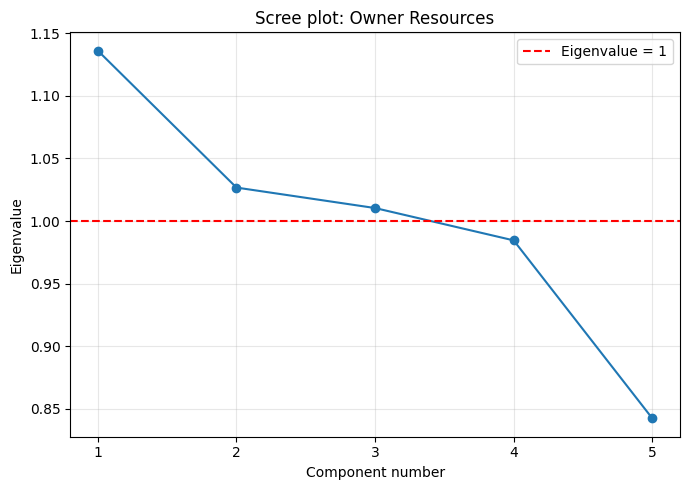


Group: staffing
Observations: 450
Variables: 12

Overall KMO: 0.6716

KMO for individual variables:


,variable,KMO
4,Admin_Staff_2020,0.4752
6,Admin_Staff_2022,0.5567
5,Admin_Staff_2021,0.6344
7,Admin_Staff_2023,0.6398
11,Tech_Staff_2023,0.6526
10,Tech_Staff_2022,0.6557
8,Tech_Staff_2020,0.6807
2,Owners_2022,0.6995
9,Tech_Staff_2021,0.7185
1,Owners_2021,0.7312


Variables with KMO below 0.50: ['Admin_Staff_2020']

Bartlett's test:
Chi-square: 6940.1061
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,3.7003,3.6574
1,2,3.4580,3.4030
2,3,2.7628,2.6879
3,4,0.7512,0.6367
4,5,0.6470,0.4636
5,6,0.2411,0.1661
6,7,0.1459,0.0939
7,8,0.1270,0.0250
8,9,0.0608,0.0155
9,10,0.0556,0.0093


Number of factors suggested by eigenvalue > 1: 3


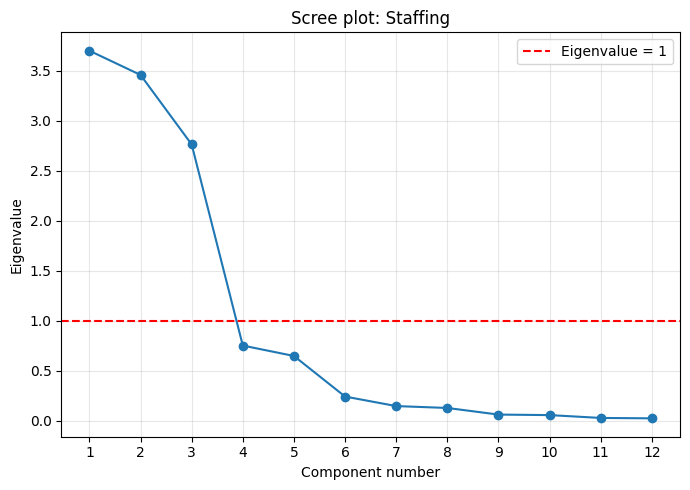


Group: operating_costs
Observations: 450
Variables: 32

Overall KMO: 0.8840

KMO for individual variables:


/usr/local/lib/python3.13/dist-packages/numpy/linalg/_linalg.py:2407: RuntimeWarning: overflow encountered in det
  r = _umath_linalg.det(a, signature=signature)


,variable,KMO
14,Finance_Cost_2022,0.0942
12,Finance_Cost_2020,0.3049
15,Finance_Cost_2023,0.3648
13,Finance_Cost_2021,0.4383
19,Rent_2023,0.4978
18,Rent_2022,0.5094
16,Rent_2020,0.6726
17,Rent_2021,0.7048
7,Cost_of_raw_materials_2023,0.8494
6,Cost_of_raw_materials_2022,0.8614


Variables with KMO below 0.50: ['Finance_Cost_2022', 'Finance_Cost_2020', 'Finance_Cost_2023', 'Finance_Cost_2021', 'Rent_2023']

Bartlett's test:
Chi-square: 29772.8677
p-value: 0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



Eigenvalues:


,component,eigenvalue,common_factor_eigenvalue
0,1,16.5004,16.4855
1,2,3.5447,3.5347
2,3,2.8246,2.8049
3,4,1.5942,1.5170
4,5,1.3241,1.2776
5,6,1.0293,0.9220
6,7,0.9921,0.6630
7,8,0.9403,0.5824
8,9,0.6151,0.4833
9,10,0.5023,0.3422


Number of factors suggested by eigenvalue > 1: 6


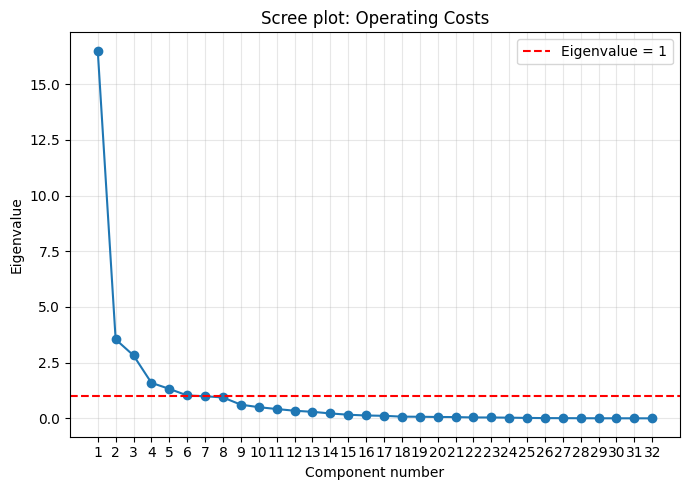


Group: business_performance
Observations: 450
Variables: 10

Overall KMO: 0.8520

KMO for individual variables:


,variable,KMO
5,Maximum_2023_Monthly_profit,0.7565
8,Other_income_total_2022,0.7652
4,Minimum_2023_Monthly_profit,0.7984
9,Other_income_total_2023,0.8239
3,Gross_annual_revenue_2023,0.8482
2,Gross_annual_revenue_2022,0.8610
0,Gross_annual_revenue_2020,0.8996
1,Gross_annual_revenue_2021,0.9301
7,Other_income_total_2021,0.9326
6,Other_income_total_2020,0.9349



Bartlett's test:
Chi-square: 11285.2272
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,4.9321,4.8631
1,2,3.9801,3.9756
2,3,0.6604,0.5651
3,4,0.2537,0.0900
4,5,0.0663,0.0176
5,6,0.0628,0.0023
6,7,0.0345,0.0010
7,8,0.0047,0.0007
8,9,0.0045,-0.0001
9,10,0.0010,-0.0019


Number of factors suggested by eigenvalue > 1: 2


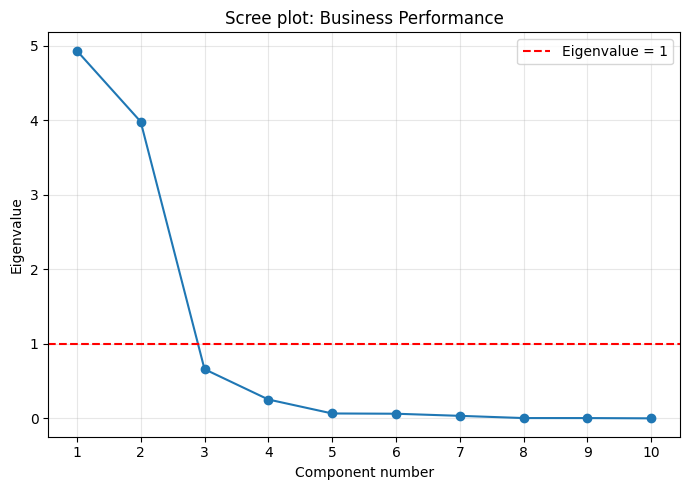


Group: investment_and_debt
Observations: 450
Variables: 16

Overall KMO: 0.5061

KMO for individual variables:


,variable,KMO
7,Cash_inflow_financial_activities_2023,0.4929
2,Cash_inflow_investing_2022,0.4970
3,Cash_inflow_investing_2023,0.4974
1,Cash_inflow_investing_2021,0.4974
0,Cash_inflow_investing_2020,0.4974
6,Cash_inflow_financial_activities_2022,0.4977
5,Cash_inflow_financial_activities_2021,0.4982
4,Cash_inflow_financial_activities_2020,0.4982
9,total_investment_2021,0.5752
8,total_investment_2020,0.6138


Variables with KMO below 0.50: ['Cash_inflow_financial_activities_2023', 'Cash_inflow_investing_2022', 'Cash_inflow_investing_2023', 'Cash_inflow_investing_2021', 'Cash_inflow_investing_2020', 'Cash_inflow_financial_activities_2022', 'Cash_inflow_financial_activities_2021', 'Cash_inflow_financial_activities_2020']

Bartlett's test:
Chi-square: 36699.6851
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,7.9590,7.9572
1,2,2.6772,2.4912
2,3,1.4230,0.6631
3,4,0.9702,0.5650
4,5,0.8770,0.0986
5,6,0.8271,0.0478
6,7,0.7606,0.0399
7,8,0.3438,0.0357
8,9,0.1201,0.0110
9,10,0.0381,0.0013


Number of factors suggested by eigenvalue > 1: 3


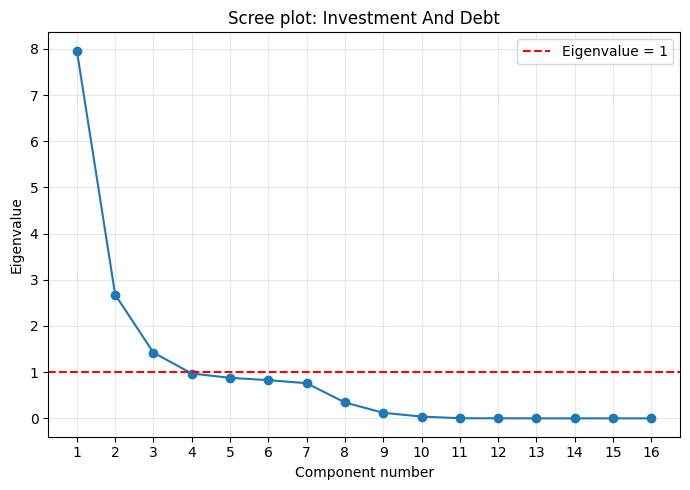

In [42]:
factor_diagnostics = {}

for group_name, group_columns in CONTINUOUS_GROUPS.items():
    factor_diagnostics[group_name] = assess_factorability(
        data=X_train_continuous_imputed[group_columns],
        group_name=group_name,
    )

In [43]:
factorability_summary = pd.DataFrame(
    [
        {
            "group": group_name,
            "variables_used": len(result["variables_used"]),
            "constant_variables_removed": len(
                result["constant_columns_removed"]
            ),
            "overall_KMO": result["overall_kmo"],
            "bartlett_chi_square": (
                result["bartlett_chi_square"]
            ),
            "bartlett_p_value": (
                result["bartlett_p_value"]
            ),
            "eigenvalues_above_1": (
                result["kaiser_factor_count"]
            ),
            "variables_with_KMO_below_0.50": len(
                result["low_kmo_variables"]
            ),
        }
        for group_name, result in factor_diagnostics.items()
    ]
)

display(factorability_summary.round(4))

,group,variables_used,constant_variables_removed,overall_KMO,bartlett_chi_square,bartlett_p_value,eigenvalues_above_1,variables_with_KMO_below_0.50
0,owner_resources,5,0,0.4809,10.2527,0.4186,3,5
1,staffing,12,0,0.6716,6940.1061,0.0000,3,1
2,operating_costs,32,0,0.8840,29772.8677,0.0000,6,5
3,business_performance,10,0,0.8520,11285.2272,0.0000,2,0
4,investment_and_debt,16,0,0.5061,36699.6851,0.0000,3,8


In [44]:
NON_FA_CONTINUOUS_COLUMNS = [
    # Owner-resource variables
    *CONTINUOUS_GROUPS["owner_resources"],

    # Other variables with individual KMO below 0.50
    "Admin_Staff_2020",
    *[f"Finance_Cost_{year}" for year in YEARS],
    "Rent_2023",

    # Cash-inflow variables
    *[
        f"Cash_inflow_investing_{year}"
        for year in YEARS
    ],
    *[
        f"Cash_inflow_financial_activities_{year}"
        for year in YEARS
    ],
]

NON_FA_CONTINUOUS_COLUMNS = list(
    dict.fromkeys(NON_FA_CONTINUOUS_COLUMNS)
)

In [45]:
REVISED_FA_GROUPS = {
    group_name: [
        column
        for column in group_columns
        if column not in NON_FA_CONTINUOUS_COLUMNS
    ]
    for group_name, group_columns in CONTINUOUS_GROUPS.items()
    if group_name != "owner_resources"
}

In [46]:
for group_name, columns in REVISED_FA_GROUPS.items():
    print(f"\n{group_name}: {len(columns)} variables")
    print(columns)


staffing: 11 variables
['Owners_2020', 'Owners_2021', 'Owners_2022', 'Owners_2023', 'Admin_Staff_2021', 'Admin_Staff_2022', 'Admin_Staff_2023', 'Tech_Staff_2020', 'Tech_Staff_2021', 'Tech_Staff_2022', 'Tech_Staff_2023']

operating_costs: 27 variables
['Employee_compensation_2020', 'Employee_compensation_2021', 'Employee_compensation_2022', 'Employee_compensation_2023', 'Cost_of_raw_materials_2020', 'Cost_of_raw_materials_2021', 'Cost_of_raw_materials_2022', 'Cost_of_raw_materials_2023', 'Utility_bills_2020', 'Utility_bills_2021', 'Utility_bills_2022', 'Utility_bills_2023', 'Rent_2020', 'Rent_2021', 'Rent_2022', 'Transport_cost_2020', 'Transport_cost_2021', 'Transport_cost_2022', 'Transport_cost_2023', 'Maintenance_cost_2020', 'Maintenance_cost_2021', 'Maintenance_cost_2022', 'Maintenance_cost_2023', 'Other_expenses_2020', 'Other_expenses_2021', 'Other_expenses_2022', 'Other_expenses_2023']

business_performance: 10 variables
['Gross_annual_revenue_2020', 'Gross_annual_revenue_2021', '


Group: staffing
Observations: 450
Variables: 11

Overall KMO: 0.7178

KMO for individual variables:


,variable,KMO
5,Admin_Staff_2022,0.6391
10,Tech_Staff_2023,0.6518
9,Tech_Staff_2022,0.6550
7,Tech_Staff_2020,0.6799
6,Admin_Staff_2023,0.6821
2,Owners_2022,0.7085
8,Tech_Staff_2021,0.7176
1,Owners_2021,0.7400
0,Owners_2020,0.7806
3,Owners_2023,0.7978



Bartlett's test:
Chi-square: 6477.3563
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,3.6900,3.6441
1,2,3.3044,3.2194
2,3,2.5131,2.4265
3,4,0.7334,0.6267
4,5,0.2492,0.1640
5,6,0.1956,0.0380
6,7,0.1352,0.0194
7,8,0.0612,0.0134
8,9,0.0558,0.0071
9,10,0.0372,0.0006


Number of factors suggested by eigenvalue > 1: 3


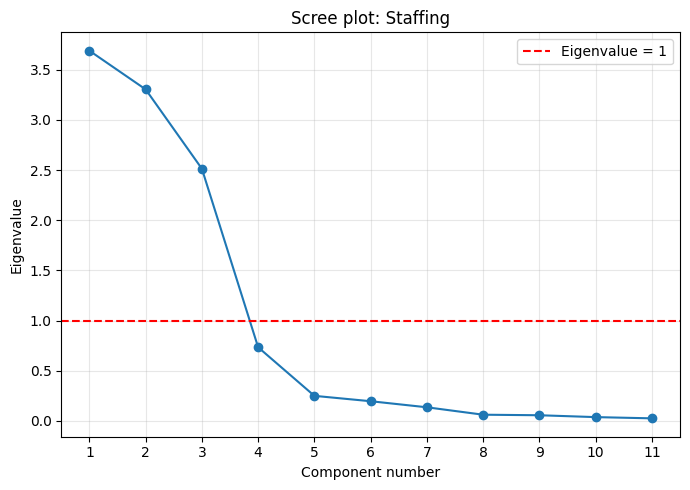


Group: operating_costs
Observations: 450
Variables: 27

Overall KMO: 0.9079

KMO for individual variables:


,variable,KMO
13,Rent_2021,0.6088
12,Rent_2020,0.6457
14,Rent_2022,0.6953
6,Cost_of_raw_materials_2022,0.8594
7,Cost_of_raw_materials_2023,0.8656
2,Employee_compensation_2022,0.8794
9,Utility_bills_2021,0.8889
20,Maintenance_cost_2021,0.8902
17,Transport_cost_2022,0.8911
1,Employee_compensation_2021,0.8922



Bartlett's test:
Chi-square: 28161.0418
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,16.4941,16.4794
1,2,3.0194,2.9921
2,3,2.6416,2.6138
3,4,1.3178,1.2702
4,5,0.8917,0.8698
5,6,0.6190,0.6100
6,7,0.3624,0.2787
7,8,0.3080,0.2326
8,9,0.2946,0.2215
9,10,0.2210,0.1549


Number of factors suggested by eigenvalue > 1: 4


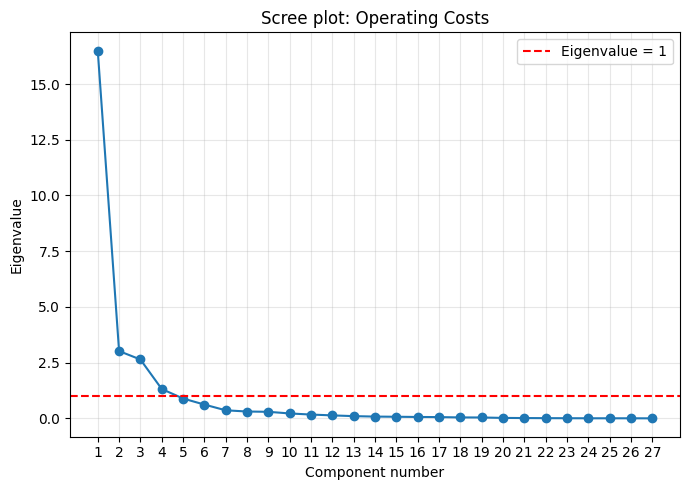


Group: business_performance
Observations: 450
Variables: 10

Overall KMO: 0.8520

KMO for individual variables:


,variable,KMO
5,Maximum_2023_Monthly_profit,0.7565
8,Other_income_total_2022,0.7652
4,Minimum_2023_Monthly_profit,0.7984
9,Other_income_total_2023,0.8239
3,Gross_annual_revenue_2023,0.8482
2,Gross_annual_revenue_2022,0.8610
0,Gross_annual_revenue_2020,0.8996
1,Gross_annual_revenue_2021,0.9301
7,Other_income_total_2021,0.9326
6,Other_income_total_2020,0.9349



Bartlett's test:
Chi-square: 11285.2272
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,4.9321,4.8631
1,2,3.9801,3.9756
2,3,0.6604,0.5651
3,4,0.2537,0.0900
4,5,0.0663,0.0176
5,6,0.0628,0.0023
6,7,0.0345,0.0010
7,8,0.0047,0.0007
8,9,0.0045,-0.0001
9,10,0.0010,-0.0019


Number of factors suggested by eigenvalue > 1: 2


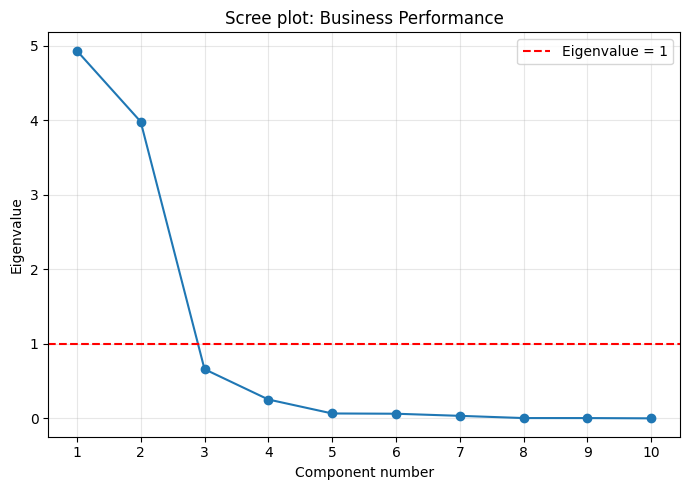


Group: investment_and_debt
Observations: 450
Variables: 8

Overall KMO: 0.6597

KMO for individual variables:


,variable,KMO
1,total_investment_2021,0.5749
0,total_investment_2020,0.6062
3,total_investment_2023,0.6103
7,non-performing_debt_2023,0.6232
2,total_investment_2022,0.6319
6,non-performing_debt_2022,0.6399
4,non-performing_debt_2020,0.6761
5,non-performing_debt_2021,0.7508



Bartlett's test:
Chi-square: 1101.8964
p-value: 3.77346e-214

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,2.6775,2.4911
1,2,1.4233,0.6614
2,3,0.9702,0.5644
3,4,0.8770,0.0966
4,5,0.8271,0.0469
5,6,0.7608,0.0393
6,7,0.3438,0.0094
7,8,0.1201,-0.0000


Number of factors suggested by eigenvalue > 1: 2


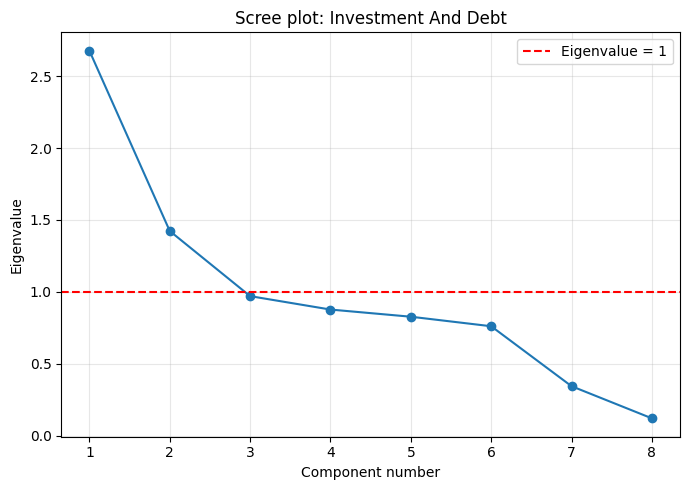

In [47]:
revised_factor_diagnostics = {}

for group_name, group_columns in REVISED_FA_GROUPS.items():
    revised_factor_diagnostics[group_name] = (
        assess_factorability(
            data=X_train_continuous_imputed[
                group_columns
            ],
            group_name=group_name,
        )
    )

In [48]:
revised_factorability_summary = pd.DataFrame(
    [
        {
            "group": group_name,
            "variables_used": len(
                result["variables_used"]
            ),
            "overall_KMO": result["overall_kmo"],
            "bartlett_chi_square": (
                result["bartlett_chi_square"]
            ),
            "bartlett_p_value": (
                result["bartlett_p_value"]
            ),
            "eigenvalues_above_1": (
                result["kaiser_factor_count"]
            ),
            "variables_with_KMO_below_0.50": len(
                result["low_kmo_variables"]
            ),
        }
        for group_name, result
        in revised_factor_diagnostics.items()
    ]
)

display(revised_factorability_summary.round(4))

,group,variables_used,overall_KMO,bartlett_chi_square,bartlett_p_value,eigenvalues_above_1,variables_with_KMO_below_0.50
0,staffing,11,0.7178,6477.3563,0.0,3,0
1,operating_costs,27,0.9079,28161.0418,0.0,4,0
2,business_performance,10,0.8520,11285.2272,0.0,2,0
3,investment_and_debt,8,0.6597,1101.8964,0.0,2,0


In [49]:
SELECTED_N_FACTORS = {
    "staffing": 3,
    "operating_costs": 4,
    "business_performance": 2,
    "investment_and_debt": 2,
}

In [50]:
def perform_FA(REVISED_FA_GROUPS, SELECTED_N_FACTORS):
    preliminary_fa_results = {}

    for group_name, variables in REVISED_FA_GROUPS.items():
        n_factors = SELECTED_N_FACTORS[group_name]

        temporary_names = [
            f"{group_name}_Factor_{number}"
            for number in range(1, n_factors + 1)
        ]

        X_group_train = (
            X_train_continuous_imputed[variables].copy()
        )

        if X_group_train.isna().any().any():
            raise ValueError(
                f"Missing values remain in {group_name}."
            )

        factor_model = FactorAnalyzer(
            n_factors=n_factors,
            method="minres",
            rotation="varimax",
            use_smc=True,
        )

        factor_model.fit(X_group_train)

        # Full rotated loading matrix
        loadings = pd.DataFrame(
            factor_model.loadings_,
            index=variables,
            columns=temporary_names,
        )

        # Show loadings whose absolute values are at least 0.50
        salient_loadings = loadings.where(
            loadings.abs() >= 0.50
        )

        # Sort variables according to their strongest factor
        loading_summary = pd.DataFrame(
            {
                "strongest_factor": loadings.abs().idxmax(axis=1),
                "strongest_absolute_loading": (
                    loadings.abs().max(axis=1)
                ),
            },
            index=variables,
        )

        loading_order = loading_summary.sort_values(
            ["strongest_factor", "strongest_absolute_loading"],
            ascending=[True, False],
        ).index

        loadings = loadings.loc[loading_order]
        salient_loadings = salient_loadings.loc[loading_order]
        loading_summary = loading_summary.loc[loading_order]

        # Variance explained
        (
            sum_squared_loadings,
            proportional_variance,
            cumulative_variance,
        ) = factor_model.get_factor_variance()

        variance_table = pd.DataFrame(
            {
                "factor": temporary_names,
                "sum_squared_loadings": sum_squared_loadings,
                "variance_percent": (
                    proportional_variance * 100
                ),
                "cumulative_variance_percent": (
                    cumulative_variance * 100
                ),
            }
        )

        # Communalities and uniquenesses
        communalities = pd.DataFrame(
            {
                "variable": variables,
                "communality": (
                    factor_model.get_communalities()
                ),
                "uniqueness": (
                    factor_model.get_uniquenesses()
                ),
            }
        ).sort_values("communality")

        # Variables without a loading of at least 0.50
        no_strong_loading = salient_loadings.index[
            salient_loadings.isna().all(axis=1)
        ].tolist()

        # Variables loading on more than one factor
        cross_loading_variables = (
            (loadings.abs() >= 0.50)
            .sum(axis=1)
        )

        cross_loading_variables = (
            cross_loading_variables[
                cross_loading_variables > 1
            ]
            .index
            .tolist()
        )

        preliminary_fa_results[group_name] = {
            "model": factor_model,
            "variables": variables,
            "temporary_names": temporary_names,
            "loadings": loadings,
            "salient_loadings": salient_loadings,
            "loading_summary": loading_summary,
            "variance": variance_table,
            "communalities": communalities,
            "no_strong_loading": no_strong_loading,
            "cross_loading_variables": (
                cross_loading_variables
            ),
        }
    return preliminary_fa_results

In [51]:
preliminary_fa_results = perform_FA(REVISED_FA_GROUPS, SELECTED_N_FACTORS)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


In [52]:
for group_name, result in preliminary_fa_results.items():
    print(f"\n{'=' * 90}")
    print(group_name.upper())
    print(f"{'=' * 90}")

    print("\nLoadings with absolute value ≥ 0.50:")
    display(result["salient_loadings"].round(3))

    print("\nVariance explained:")
    display(result["variance"].round(3))

    print("\nCommunalities and uniquenesses:")
    display(result["communalities"].round(3))

    print(
        "\nVariables without a loading ≥ 0.50:",
        result["no_strong_loading"],
    )

    print(
        "Variables with cross-loadings ≥ 0.50:",
        result["cross_loading_variables"],
    )


STAFFING

Loadings with absolute value ≥ 0.50:


,staffing_Factor_1,staffing_Factor_2,staffing_Factor_3
Owners_2021,0.989,NaN,NaN
Owners_2022,0.972,NaN,NaN
Owners_2023,0.943,NaN,NaN
Owners_2020,0.867,NaN,NaN
Tech_Staff_2022,NaN,0.891,NaN
Tech_Staff_2021,NaN,0.860,NaN
Tech_Staff_2023,NaN,0.850,NaN
Tech_Staff_2020,NaN,0.716,NaN
Admin_Staff_2022,NaN,NaN,0.996
Admin_Staff_2023,NaN,NaN,0.956



Variance explained:


,factor,sum_squared_loadings,variance_percent,cumulative_variance_percent
0,staffing_Factor_1,3.565,32.405,32.405
1,staffing_Factor_2,2.785,25.317,57.722
2,staffing_Factor_3,2.658,24.167,81.889



Communalities and uniquenesses:


,variable,communality,uniqueness
7,Tech_Staff_2020,0.515,0.485
10,Tech_Staff_2023,0.726,0.274
4,Admin_Staff_2021,0.743,0.257
8,Tech_Staff_2021,0.745,0.255
0,Owners_2020,0.755,0.245
9,Tech_Staff_2022,0.797,0.203
3,Owners_2023,0.891,0.109
6,Admin_Staff_2023,0.916,0.084
2,Owners_2022,0.944,0.056
1,Owners_2021,0.978,0.022


... (15 outputs left out)

,factor,sum_squared_loadings,variance_percent,cumulative_variance_percent
0,investment_and_debt_Factor_1,2.322,29.021,29.021
1,investment_and_debt_Factor_2,0.631,7.885,36.906



Communalities and uniquenesses:


,variable,communality,uniqueness
2,total_investment_2022,0.039,0.961
0,total_investment_2020,0.126,0.874
3,total_investment_2023,0.153,0.847
4,non-performing_debt_2020,0.239,0.761
1,total_investment_2021,0.315,0.685
5,non-performing_debt_2021,0.543,0.457
6,non-performing_debt_2022,0.740,0.260
7,non-performing_debt_2023,0.797,0.203



Variables without a loading ≥ 0.50: ['non-performing_debt_2020', 'total_investment_2023', 'total_investment_2020', 'total_investment_2022']
Variables with cross-loadings ≥ 0.50: []


In [53]:
def summarize_variables_by_factor(
    loadings: pd.DataFrame,
    threshold: float = 0.50,
) -> dict:
    summary = {}

    for factor in loadings.columns:
        selected = loadings.loc[
            loadings[factor].abs() >= threshold,
            factor,
        ]

        selected = selected.reindex(
            selected.abs().sort_values(
                ascending=False
            ).index
        )

        summary[factor] = selected

    return summary

In [54]:
for group_name, result in preliminary_fa_results.items():
    print(f"\n{'=' * 80}")
    print(f"FACTOR-NAMING SUMMARY: {group_name.upper()}")
    print(f"{'=' * 80}")

    naming_summary = summarize_variables_by_factor(
        result["loadings"],
        threshold=0.50,
    )

    for factor, contributing_variables in (
        naming_summary.items()
    ):
        print(f"\n{factor}")

        if contributing_variables.empty:
            print("No variables have an absolute loading ≥ 0.50.")
        else:
            display(
                contributing_variables
                .rename("loading")
                .to_frame()
                .round(3)
            )


FACTOR-NAMING SUMMARY: STAFFING

staffing_Factor_1


,loading
Owners_2021,0.989
Owners_2022,0.972
Owners_2023,0.943
Owners_2020,0.867



staffing_Factor_2


,loading
Tech_Staff_2022,0.891
Tech_Staff_2021,0.860
Tech_Staff_2023,0.850
Tech_Staff_2020,0.716



staffing_Factor_3


,loading
Admin_Staff_2022,0.996
Admin_Staff_2023,0.956
Admin_Staff_2021,0.858


... (12 outputs left out)


FACTOR-NAMING SUMMARY: INVESTMENT_AND_DEBT

investment_and_debt_Factor_1


,loading
non-performing_debt_2023,0.892
non-performing_debt_2022,0.860
non-performing_debt_2021,0.736



investment_and_debt_Factor_2


,loading
total_investment_2021,0.561


In [55]:
DEBT_FACTOR_COLUMNS = [
    "non-performing_debt_2021",
    "non-performing_debt_2022",
    "non-performing_debt_2023",
]

INVESTMENT_NON_FA_COLUMNS = [
    "non-performing_debt_2020",
    *[f"total_investment_{year}" for year in YEARS],
]

In [56]:
REVISED_FA_GROUPS["investment_and_debt"] = (
    DEBT_FACTOR_COLUMNS
)

In [57]:
SELECTED_N_FACTORS = {
    "staffing": 3,
    "operating_costs": 4,
    "business_performance": 2,
    "investment_and_debt": 1,
}

preliminary_fa_results = perform_FA(REVISED_FA_GROUPS, SELECTED_N_FACTORS)
for group_name, result in preliminary_fa_results.items():
    print(f"\n{'=' * 90}")
    print(group_name.upper())
    print(f"{'=' * 90}")

    print("\nLoadings with absolute value ≥ 0.50:")
    display(result["salient_loadings"].round(3))

    print("\nVariance explained:")
    display(result["variance"].round(3))

    print("\nCommunalities and uniquenesses:")
    display(result["communalities"].round(3))

    print(
        "\nVariables without a loading ≥ 0.50:",
        result["no_strong_loading"],
    )

    print(
        "Variables with cross-loadings ≥ 0.50:",
        result["cross_loading_variables"],
    )

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



STAFFING

Loadings with absolute value ≥ 0.50:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/factor_analyzer/factor_analyzer.py:663: UserWarning: No rotation will be performed when the number of factors equals 1.
  warnings.warn(


,staffing_Factor_1,staffing_Factor_2,staffing_Factor_3
Owners_2021,0.989,NaN,NaN
Owners_2022,0.972,NaN,NaN
Owners_2023,0.943,NaN,NaN
Owners_2020,0.867,NaN,NaN
Tech_Staff_2022,NaN,0.891,NaN
Tech_Staff_2021,NaN,0.860,NaN
Tech_Staff_2023,NaN,0.850,NaN
Tech_Staff_2020,NaN,0.716,NaN
Admin_Staff_2022,NaN,NaN,0.996
Admin_Staff_2023,NaN,NaN,0.956



Variance explained:


,factor,sum_squared_loadings,variance_percent,cumulative_variance_percent
0,staffing_Factor_1,3.565,32.405,32.405
1,staffing_Factor_2,2.785,25.317,57.722
2,staffing_Factor_3,2.658,24.167,81.889


... (17 outputs left out)

,factor,sum_squared_loadings,variance_percent,cumulative_variance_percent
0,investment_and_debt_Factor_1,2.143,71.425,71.425



Communalities and uniquenesses:


,variable,communality,uniqueness
0,non-performing_debt_2021,0.385,0.615
1,non-performing_debt_2022,0.815,0.185
2,non-performing_debt_2023,0.943,0.057



Variables without a loading ≥ 0.50: []
Variables with cross-loadings ≥ 0.50: []


In [58]:
NON_FA_CONTINUOUS_COLUMNS = list(
    dict.fromkeys(
        NON_FA_CONTINUOUS_COLUMNS
        + INVESTMENT_NON_FA_COLUMNS
    )
)

In [59]:
FINAL_FACTOR_NAMES = {
    "staffing": [
        "FA_Owner_Staffing_Capacity",
        "FA_Technical_Staffing_Capacity",
        "FA_Administrative_Staffing_Capacity",
    ],
    "operating_costs": [
        "FA_General_Operating_and_Logistics_Costs",
        "FA_Utility_Cost_Burden",
        "FA_Employee_and_Raw_Material_Costs",
        "FA_Rental_Cost_Burden",
    ],
    "business_performance": [
        "FA_Revenue_and_Profit_Performance",
        "FA_Other_Income_Capacity",
    ],
    "investment_and_debt": [
        "FA_Nonperforming_Debt_Burden",
    ],
}

In [60]:
for group_name, names in FINAL_FACTOR_NAMES.items():
    expected = SELECTED_N_FACTORS[group_name]

    if len(names) != expected:
        raise ValueError(
            f"{group_name} requires {expected} names, "
            f"but {len(names)} were supplied."
        )

    if len(names) != len(set(names)):
        raise ValueError(
            f"{group_name} contains duplicate factor names."
        )


Group: staffing
Observations: 450
Variables: 11

Overall KMO: 0.7178

KMO for individual variables:


,variable,KMO
5,Admin_Staff_2022,0.6391
10,Tech_Staff_2023,0.6518
9,Tech_Staff_2022,0.6550
7,Tech_Staff_2020,0.6799
6,Admin_Staff_2023,0.6821
2,Owners_2022,0.7085
8,Tech_Staff_2021,0.7176
1,Owners_2021,0.7400
0,Owners_2020,0.7806
3,Owners_2023,0.7978



Bartlett's test:
Chi-square: 6477.3563
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,3.6900,3.6441
1,2,3.3044,3.2194
2,3,2.5131,2.4265
3,4,0.7334,0.6267
4,5,0.2492,0.1640
5,6,0.1956,0.0380
6,7,0.1352,0.0194
7,8,0.0612,0.0134
8,9,0.0558,0.0071
9,10,0.0372,0.0006


Number of factors suggested by eigenvalue > 1: 3


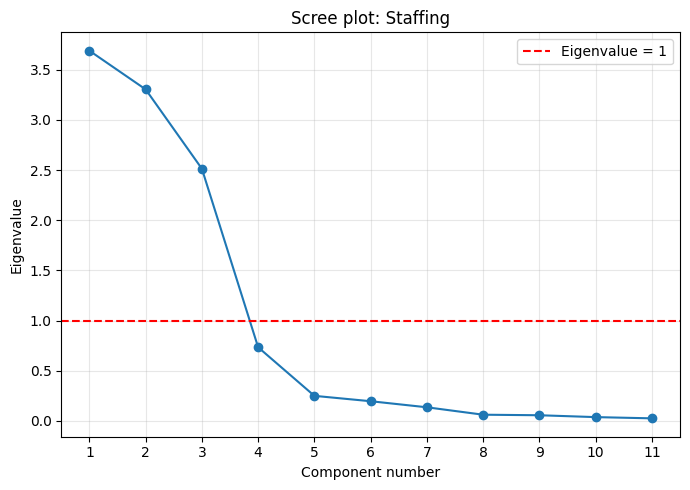


Group: operating_costs
Observations: 450
Variables: 27

Overall KMO: 0.9079

KMO for individual variables:


,variable,KMO
13,Rent_2021,0.6088
12,Rent_2020,0.6457
14,Rent_2022,0.6953
6,Cost_of_raw_materials_2022,0.8594
7,Cost_of_raw_materials_2023,0.8656
2,Employee_compensation_2022,0.8794
9,Utility_bills_2021,0.8889
20,Maintenance_cost_2021,0.8902
17,Transport_cost_2022,0.8911
1,Employee_compensation_2021,0.8922



Bartlett's test:
Chi-square: 28161.0418
p-value: 0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



Eigenvalues:


,component,eigenvalue,common_factor_eigenvalue
0,1,16.4941,16.4794
1,2,3.0194,2.9921
2,3,2.6416,2.6138
3,4,1.3178,1.2702
4,5,0.8917,0.8698
5,6,0.6190,0.6100
6,7,0.3624,0.2787
7,8,0.3080,0.2326
8,9,0.2946,0.2215
9,10,0.2210,0.1549


Number of factors suggested by eigenvalue > 1: 4


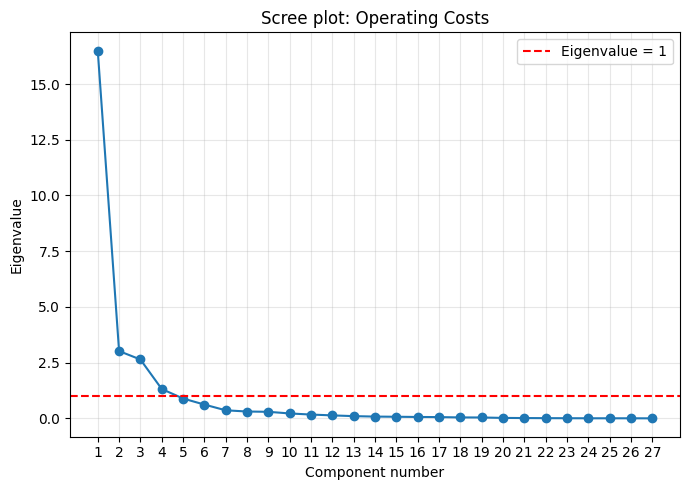


Group: business_performance
Observations: 450
Variables: 10

Overall KMO: 0.8520

KMO for individual variables:


,variable,KMO
5,Maximum_2023_Monthly_profit,0.7565
8,Other_income_total_2022,0.7652
4,Minimum_2023_Monthly_profit,0.7984
9,Other_income_total_2023,0.8239
3,Gross_annual_revenue_2023,0.8482
2,Gross_annual_revenue_2022,0.8610
0,Gross_annual_revenue_2020,0.8996
1,Gross_annual_revenue_2021,0.9301
7,Other_income_total_2021,0.9326
6,Other_income_total_2020,0.9349



Bartlett's test:
Chi-square: 11285.2272
p-value: 0

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,4.9321,4.8631
1,2,3.9801,3.9756
2,3,0.6604,0.5651
3,4,0.2537,0.0900
4,5,0.0663,0.0176
5,6,0.0628,0.0023
6,7,0.0345,0.0010
7,8,0.0047,0.0007
8,9,0.0045,-0.0001
9,10,0.0010,-0.0019


Number of factors suggested by eigenvalue > 1: 2


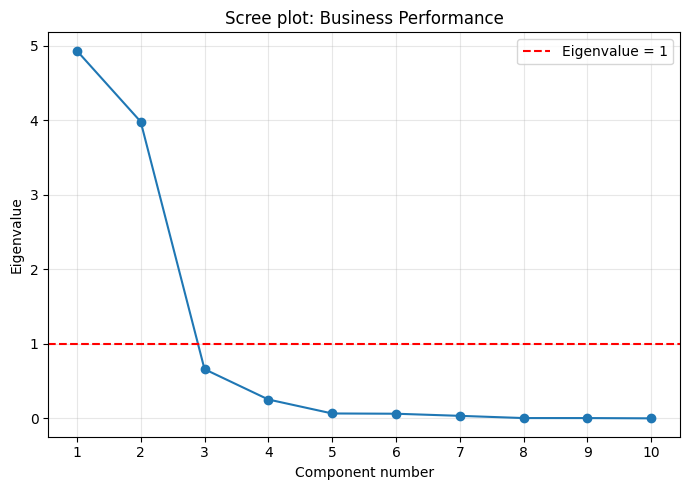


Group: investment_and_debt
Observations: 450
Variables: 3

Overall KMO: 0.6584

KMO for individual variables:


,variable,KMO
2,non-performing_debt_2023,0.6036
1,non-performing_debt_2022,0.6170
0,non-performing_debt_2021,0.8884



Bartlett's test:
Chi-square: 858.7634
p-value: 7.78529e-186

Eigenvalues:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,component,eigenvalue,common_factor_eigenvalue
0,1,2.3700,2.1525
1,2,0.5083,0.0385
2,3,0.1216,-0.0000


Number of factors suggested by eigenvalue > 1: 1


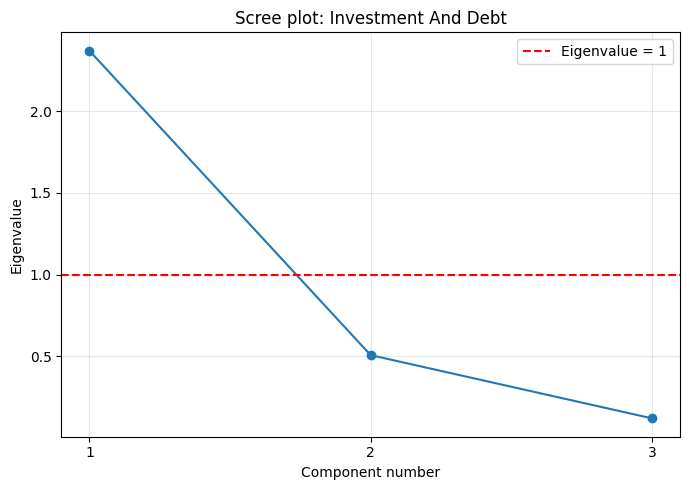

,group,variables_used,overall_KMO,bartlett_chi_square,bartlett_p_value,eigenvalues_above_1,variables_with_KMO_below_0.50
0,staffing,11,0.7178,6477.3563,0.0,3,0
1,operating_costs,27,0.9079,28161.0418,0.0,4,0
2,business_performance,10,0.8520,11285.2272,0.0,2,0
3,investment_and_debt,3,0.6584,858.7634,0.0,1,0


In [61]:
revised_factor_diagnostics = {}

for group_name, group_columns in REVISED_FA_GROUPS.items():
    revised_factor_diagnostics[group_name] = (
        assess_factorability(
            data=X_train_continuous_imputed[
                group_columns
            ],
            group_name=group_name,
        )
    )

revised_factorability_summary = pd.DataFrame(
    [
        {
            "group": group_name,
            "variables_used": len(
                result["variables_used"]
            ),
            "overall_KMO": result["overall_kmo"],
            "bartlett_chi_square": (
                result["bartlett_chi_square"]
            ),
            "bartlett_p_value": (
                result["bartlett_p_value"]
            ),
            "eigenvalues_above_1": (
                result["kaiser_factor_count"]
            ),
            "variables_with_KMO_below_0.50": len(
                result["low_kmo_variables"]
            ),
        }
        for group_name, result
        in revised_factor_diagnostics.items()
    ]
)

display(revised_factorability_summary.round(4))

# 11. Leakage-safe Phase 2 feature builder

The Phase 2 feature definitions and factor counts were selected using the
training set only. During model tuning, the transformations below are refitted
inside every CV fold. Validation and test data never fit an imputer, scaler,
or factor model.


In [62]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
)
from sklearn.model_selection import KFold, ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from factor_analyzer import FactorAnalyzer

In [63]:
class Phase2FeatureBuilder:
    """Fit all Phase 2 preprocessing using training rows only."""

    def fit(self, df: pd.DataFrame):
        missing = sorted(
            set(CONTINUOUS_COLUMNS + CATEGORICAL_COLUMNS) - set(df.columns)
        )
        if missing:
            raise ValueError(f"Missing Phase 2 predictor columns: {missing}")

        self.continuous_imputer_ = SimpleImputer(
            strategy="median",
            keep_empty_features=True,
        )
        self.categorical_imputer_ = SimpleImputer(
            strategy="most_frequent",
            keep_empty_features=True,
        )

        continuous = pd.DataFrame(
            self.continuous_imputer_.fit_transform(df[CONTINUOUS_COLUMNS]),
            columns=CONTINUOUS_COLUMNS,
            index=df.index,
        )
        self.categorical_imputer_.fit(df[CATEGORICAL_COLUMNS])

        self.factor_models_ = {}
        for group_name, variables in REVISED_FA_GROUPS.items():
            n_factors = SELECTED_N_FACTORS[group_name]
            rotation = "varimax" if n_factors > 1 else None
            model = FactorAnalyzer(
                n_factors=n_factors,
                method="minres",
                rotation=rotation,
                use_smc=True,
            )
            model.fit(continuous[variables])
            self.factor_models_[group_name] = model

        self.non_fa_scaler_ = StandardScaler()
        self.non_fa_scaler_.fit(continuous[NON_FA_CONTINUOUS_COLUMNS])

        transformed = self.transform(df)
        self.feature_columns_ = transformed.columns.tolist()
        return self

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        continuous = pd.DataFrame(
            self.continuous_imputer_.transform(df[CONTINUOUS_COLUMNS]),
            columns=CONTINUOUS_COLUMNS,
            index=df.index,
        )
        categorical = pd.DataFrame(
            self.categorical_imputer_.transform(df[CATEGORICAL_COLUMNS]),
            columns=CATEGORICAL_COLUMNS,
            index=df.index,
            dtype=float,
        )

        factor_frames = []
        for group_name, variables in REVISED_FA_GROUPS.items():
            factor_frames.append(
                pd.DataFrame(
                    self.factor_models_[group_name].transform(continuous[variables]),
                    columns=FINAL_FACTOR_NAMES[group_name],
                    index=df.index,
                )
            )

        non_fa = pd.DataFrame(
            self.non_fa_scaler_.transform(
                continuous[NON_FA_CONTINUOUS_COLUMNS]
            ),
            columns=NON_FA_CONTINUOUS_COLUMNS,
            index=df.index,
        )

        result = pd.concat([*factor_frames, non_fa, categorical], axis=1)
        if result.columns.duplicated().any():
            duplicates = result.columns[result.columns.duplicated()].tolist()
            raise ValueError(f"Duplicate Phase 2 predictors: {duplicates}")
        if result.isna().any().any() or np.isinf(result.to_numpy()).any():
            raise ValueError("Invalid values remain in Phase 2 predictors.")
        return result

    def fit_transform(self, df: pd.DataFrame) -> pd.DataFrame:
        return self.fit(df).transform(df)


In [64]:
def clip_probability(predictions):
    return np.clip(np.asarray(predictions, dtype=float), 0.0, 1.0)


def probability_metrics(y_true, y_pred) -> dict:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = clip_probability(y_pred)
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
    }


In [65]:
def make_phase2_regressor_search_spaces():
    return {
        "Ridge": (
            Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
            {"model__alpha": np.logspace(-4, 4, 30).tolist()},
        ),
        "Random Forest Regressor": (
            Pipeline([("model", RandomForestRegressor(
                random_state=RANDOM_STATE, n_jobs=-1
            ))]),
            {
                "model__n_estimators": [400, 700, 1000],
                "model__max_depth": [5, 8, 12, 16, None],
                "model__min_samples_split": [5, 10, 20],
                "model__min_samples_leaf": [2, 4, 8, 12],
                "model__max_features": ["sqrt", 0.3, 0.5, 0.7],
                "model__max_samples": [0.6, 0.75, 0.9, 1.0],
            },
        ),
        "Hist Gradient Boosting Regressor": (
            Pipeline([("model", HistGradientBoostingRegressor(
                random_state=RANDOM_STATE
            ))]),
            {
                "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
                "model__max_iter": [100, 200, 400],
                "model__max_leaf_nodes": [7, 15, 31],
                "model__min_samples_leaf": [10, 20, 30],
                "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
            },
        ),
        "XGBoost Regressor": (
            Pipeline([("model", XGBRegressor(
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ))]),
            {
                "model__n_estimators": [450,500,550],
                "model__max_depth": [4, 5, 6, 7],
                "model__learning_rate": [0.02, 0.03, 0.05, 1.0],
                "model__min_child_weight": [10, 12, 13, 14],
                "model__subsample": [0.80, 0.85, 0.90],
                "model__colsample_bytree": [0.3, 0.4, 0.5],
                "model__reg_alpha": [0.0, 0.01, 0.1, 1.0],
                "model__reg_lambda": [0.01, 0.1, 0.5, 1.0],
            },
        ),
        "LightGBM Regressor": (
            Pipeline([("model", LGBMRegressor(
                objective="regression",
                random_state=RANDOM_STATE,
                n_jobs=-1,
                verbose=-1,
                importance_type="gain",
            ))]),
            {
                "model__n_estimators": [600, 700, 750],
                "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
                "model__num_leaves": [10, 15, 20, 40],
                "model__max_depth": [7, 8, 9, 10],
                "model__min_child_samples": [4, 5, 6, 7],
                "model__colsample_bytree": [0.2, 0.4, 0.5],
                "model__reg_alpha": [0.0, 0.01, 0.1, 1.0],
                "model__reg_lambda": [0.0, 0.1, 1.0, 10.0],
            },
        ),
    }


# 12. Leakage-safe Phase 2 tuning and validation selection

The preprocessing is prepared once per fold and reused across hyperparameter
candidates. Models are tuned only on training folds. Each model's best
combination is refitted on the complete training set and compared on validation
RMSE. The test set remains untouched until the final selected model.


In [66]:
def tune_phase2_regressors(
    train_raw: pd.DataFrame,
    y_train_probability,
    validation_raw: pd.DataFrame,
    y_validation_probability,
    n_iter: int = 20,
    cv_folds: int = 5,
):
    y_train_probability = np.asarray(y_train_probability, dtype=float)
    y_validation_probability = np.asarray(y_validation_probability, dtype=float)
    cv = KFold(
        n_splits=cv_folds,
        shuffle=True,
        random_state=RANDOM_STATE,
    )

    prepared_folds = []
    for fold_train_idx, fold_valid_idx in cv.split(train_raw):
        builder = Phase2FeatureBuilder()
        X_fold_train = builder.fit_transform(train_raw.iloc[fold_train_idx])
        X_fold_valid = builder.transform(train_raw.iloc[fold_valid_idx])
        prepared_folds.append((
            X_fold_train,
            y_train_probability[fold_train_idx],
            X_fold_valid,
            y_train_probability[fold_valid_idx],
        ))

    final_builder = Phase2FeatureBuilder()
    X_train_final = final_builder.fit_transform(train_raw)
    X_validation_final = final_builder.transform(validation_raw)

    rows = []
    fitted = {}
    for model_name, (pipeline, parameter_space) in (
        make_phase2_regressor_search_spaces().items()
    ):
        print(f"\nTuning {model_name}")
        candidates = list(ParameterSampler(
            parameter_space,
            n_iter=n_iter,
            random_state=RANDOM_STATE,
        ))
        candidate_rows = []

        for parameters in candidates:
            fold_rmses = []
            for X_fold_train, y_fold_train, X_fold_valid, y_fold_valid in prepared_folds:
                model = clone(pipeline).set_params(**parameters)
                model.fit(X_fold_train, y_fold_train)
                prediction = clip_probability(model.predict(X_fold_valid))
                fold_rmses.append(
                    probability_metrics(y_fold_valid, prediction)["rmse"]
                )
            candidate_rows.append({
                "parameters": parameters,
                "cv_rmse": float(np.mean(fold_rmses)),
                "cv_rmse_std": float(np.std(fold_rmses, ddof=1)),
            })

        best_candidate = min(candidate_rows, key=lambda row: row["cv_rmse"])
        final_model = clone(pipeline).set_params(**best_candidate["parameters"])
        final_model.fit(X_train_final, y_train_probability)
        validation_prediction = clip_probability(
            final_model.predict(X_validation_final)
        )
        validation_metrics = probability_metrics(
            y_validation_probability,
            validation_prediction,
        )

        rows.append({
            "model": model_name,
            "cv_rmse": best_candidate["cv_rmse"],
            "cv_rmse_std": best_candidate["cv_rmse_std"],
            "validation_rmse": validation_metrics["rmse"],
            "validation_mae": validation_metrics["mae"],
            "validation_r2": validation_metrics["r2"],
            "best_parameters": best_candidate["parameters"],
        })
        fitted[model_name] = {
            "model": final_model,
            "builder": final_builder,
            "candidate_results": pd.DataFrame(candidate_rows).sort_values("cv_rmse"),
            "validation_prediction": validation_prediction,
        }
        print("Best CV RMSE:", round(best_candidate["cv_rmse"], 6))
        print("Validation RMSE:", round(validation_metrics["rmse"], 6))

    comparison = pd.DataFrame(rows).sort_values(
        ["validation_rmse", "validation_mae", "validation_r2"],
        ascending=[True, True, False],
    ).reset_index(drop=True)
    best_name = str(comparison.loc[0, "model"])
    return {
        "best_name": best_name,
        "best_info": fitted[best_name],
        "all_models": fitted,
        "comparison": comparison,
        "X_train_final": X_train_final,
        "X_validation_final": X_validation_final,
    }


In [67]:
phase2_tuning = tune_phase2_regressors(
    train_raw=train_phase2_df,
    y_train_probability=train_df[PHASE2_TARGET_COL],
    validation_raw=validation_phase2_df,
    y_validation_probability=validation_df[PHASE2_TARGET_COL],
    n_iter=20,
    cv_folds=5,
)

display(phase2_tuning["comparison"].round(6))
print("Selected model:", phase2_tuning["best_name"])
print("Best parameters:")
print(
    phase2_tuning["comparison"].loc[0, "best_parameters"]
)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13


Tuning Ridge
Best CV RMSE: 0.288659
Validation RMSE: 0.314053

Tuning Random Forest Regressor
Best CV RMSE: 0.211107
Validation RMSE: 0.174347

Tuning Hist Gradient Boosting Regressor
Best CV RMSE: 0.188643
Validation RMSE: 0.158157

Tuning XGBoost Regressor
Best CV RMSE: 0.182482
Validation RMSE: 0.165097

Tuning LightGBM Regressor
Best CV RMSE: 0.182031
Validation RMSE: 0.156996


,model,cv_rmse,cv_rmse_std,validation_rmse,validation_mae,validation_r2,best_parameters
0,LightGBM Regressor,0.182031,0.021505,0.156996,0.109110,0.812065,"{'model__reg_lambda': 1.0, 'model__reg_alpha':..."
1,Hist Gradient Boosting Regressor,0.188643,0.034922,0.158157,0.108328,0.809277,"{'model__min_samples_leaf': 10, 'model__max_le..."
2,XGBoost Regressor,0.182482,0.025065,0.165097,0.115447,0.792172,"{'model__subsample': 0.9, 'model__reg_lambda':..."
3,Random Forest Regressor,0.211107,0.020739,0.174347,0.129964,0.768230,"{'model__n_estimators': 1000, 'model__min_samp..."
4,Ridge,0.288659,0.014468,0.314053,0.248640,0.247968,{'model__alpha': 117.21022975334793}


Selected model: LightGBM Regressor
Best parameters:
{'model__reg_lambda': 1.0, 'model__reg_alpha': 0.1, 'model__num_leaves': 10, 'model__n_estimators': 700, 'model__min_child_samples': 6, 'model__max_depth': 7, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.4}


In [68]:
X_train_final = phase2_tuning["X_train_final"]
X_validation_final = phase2_tuning["X_validation_final"]


# 13. One-time Phase 2 test evaluation

The first table measures how closely Phase 2 reproduces the Phase 1 active
probability. The second evaluates the resulting closure probability against
the observed business status, which is the end-to-end predictive assessment.


In [69]:
best_phase2_name = phase2_tuning["best_name"]
best_phase2_model = phase2_tuning["best_info"]["model"]
best_phase2_builder = phase2_tuning["best_info"]["builder"]

X_test_phase2 = best_phase2_builder.transform(test_phase2_df)
phase2_test_active_probability = clip_probability(
    best_phase2_model.predict(X_test_phase2)
)
phase2_fidelity_metrics = probability_metrics(
    test_df[PHASE2_TARGET_COL],
    phase2_test_active_probability,
)

phase2_test_closed_probability = 1.0 - phase2_test_active_probability
y_test_closed = test_df[TARGET_COL].to_numpy(dtype=int)
phase2_test_closed_prediction = (
    phase2_test_closed_probability >= best_threshold
).astype(int)
phase2_end_to_end_metrics = {
    "roc_auc": float(roc_auc_score(y_test_closed, phase2_test_closed_probability)),
    "pr_auc": float(average_precision_score(
        y_test_closed, phase2_test_closed_probability
    )),
    "brier_score": float(brier_score_loss(
        y_test_closed, phase2_test_closed_probability
    )),
    "balanced_accuracy": float(balanced_accuracy_score(
        y_test_closed, phase2_test_closed_prediction
    )),
    "macro_f1": float(f1_score(
        y_test_closed, phase2_test_closed_prediction, average="macro"
    )),
}

print("Selected Phase 2 model:", best_phase2_name)
print("\nFidelity to Phase 1 probability:")
display(pd.Series(phase2_fidelity_metrics).round(6))
print("\nEnd-to-end performance against Business_Status:")
display(pd.Series(phase2_end_to_end_metrics).round(6))


Selected Phase 2 model: LightGBM Regressor

Fidelity to Phase 1 probability:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


,0
rmse,0.156735
mae,0.103754
r2,0.800640



End-to-end performance against Business_Status:


,0
roc_auc,0.952468
pr_auc,0.908915
brier_score,0.064181
balanced_accuracy,0.855173
macro_f1,0.890389


In [70]:
phase2_test_results = pd.DataFrame({
    ID_COL: test_df[ID_COL].to_numpy(),
    TARGET_COL: y_test_closed,
    "phase1_active_probability": test_df[PHASE2_TARGET_COL].to_numpy(),
    "phase2_active_probability": phase2_test_active_probability,
    "phase2_closed_probability": phase2_test_closed_probability,
    "phase2_predicted_status": phase2_test_closed_prediction,
})

phase2_test_results.to_csv(
    OUTPUT_DIR / "phase2_test_predictions.csv",
    index=False,
)
pd.DataFrame([{
    "model": best_phase2_name,
    **{f"fidelity_{key}": value for key, value in phase2_fidelity_metrics.items()},
    **{f"end_to_end_{key}": value for key, value in phase2_end_to_end_metrics.items()},
}]).to_csv(OUTPUT_DIR / "phase2_test_metrics.csv", index=False)

joblib.dump(
    {
        "feature_builder": best_phase2_builder,
        "model": best_phase2_model,
        "phase1_closed_threshold": best_threshold,
        "factor_names": FINAL_FACTOR_NAMES,
        "non_fa_continuous_columns": NON_FA_CONTINUOUS_COLUMNS,
        "categorical_columns": CATEGORICAL_COLUMNS,
    },
    OUTPUT_DIR / "phase2_surrogate_model.joblib",
)

display(phase2_test_results.head())


,ID,Business_Status,phase1_active_probability,phase2_active_probability,phase2_closed_probability,phase2_predicted_status
0,Micro-109,0,0.974136,0.928114,0.071886,0
1,Micro-391,0,0.911163,0.872187,0.127813,0
2,Micro-258,0,0.854959,0.778026,0.221974,0
3,Micro-622,0,0.953127,0.845234,0.154766,0
4,Micro-303,0,0.928581,0.780605,0.219395,0


## Methodological interpretation

- Phase 1 is a status-at-2024 model, not a prospective early-warning model,
  unless all predictors are known before the outcome period.
- Phase 2 is a surrogate model trained to reproduce Phase 1 probabilities.
  Its RMSE and R² describe fidelity to Phase 1, not causal effects or direct
  closure risk.
- All annual variables are censored at and after closure. This avoids using
  values recorded after the outcome, but the resulting missing-history pattern
  can still reveal that a firm had already closed. Conclusions must therefore
  remain status-at-cutoff conclusions.
- For a direct Phase 2 closure model, use `Business_Status` as the target and
  repeat the classification workflow instead of regressing on Phase 1 output.


In [ ]:
# ============================================================
# SHAP ANALYSIS FOR PHASE 2 MODEL
# ============================================================

# Run once if SHAP is not installed
try:
    import shap
except ImportError:
    import sys
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("model") # Ensure output_dir is a Path object
shap_output_dir = output_dir / "phase2_shap_outputs" # Use Path / operator for concatenation
shap_output_dir.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Prepare model and data for SHAP
# ------------------------------------------------------------

def get_final_model_and_input(pipeline, X):
    """
    If phase2_model is a sklearn Pipeline, separate the final model
    from any preprocessing steps inside the pipeline.
    """
    if hasattr(pipeline, "named_steps") and "model" in pipeline.named_steps:
        final_model = pipeline.named_steps["model"]
        preprocessing_steps = pipeline[:-1]

        if len(preprocessing_steps.steps) > 0:
            X_transformed = preprocessing_steps.transform(X)
            X_transformed = pd.DataFrame(
                X_transformed,
                columns=X.columns,
                index=X.index
            )
        else:
            X_transformed = X.copy()
    else:
        final_model = pipeline
        X_transformed = X.copy()

    return final_model, X_transformed


phase2_inner_model, X2_train_shap = get_final_model_and_input(best_phase2_model, X_train_final)
_, X2_test_shap = get_final_model_and_input(best_phase2_model, X_test_phase2)

print("Phase 2 best model:", best_phase2_name)
print("Model used for SHAP:", type(phase2_inner_model).__name__)
print("SHAP training data shape:", X2_train_shap.shape)
print("SHAP test data shape:", X2_test_shap.shape)

Phase 2 best model: LightGBM Regressor
Model used for SHAP: LGBMRegressor
SHAP training data shape: (450, 63)
SHAP test data shape: (151, 63)


In [72]:
# ------------------------------------------------------------
# 2. Compute SHAP values - corrected for XGBoost categorical splits
# ------------------------------------------------------------

# Explain the test set
# If your test set is very large, sample it for faster plotting
explain_size = min(300, len(X2_test_shap))

if len(X2_test_shap) > explain_size:
    X2_explain = shap.sample(
        X2_test_shap,
        explain_size,
        random_state=RANDOM_STATE
    )
else:
    X2_explain = X2_test_shap.copy()


model_name_lower = type(phase2_inner_model).__name__.lower()
model_module_lower = type(phase2_inner_model).__module__.lower()

print("Model name:", type(phase2_inner_model).__name__)
print("Model module:", type(phase2_inner_model).__module__)


# XGBoost with categorical splits needs tree_path_dependent
if "xgb" in model_name_lower or "xgboost" in model_module_lower:
    explainer = shap.TreeExplainer(
        phase2_inner_model,
        feature_perturbation="tree_path_dependent"
    )

elif any(keyword in model_name_lower for keyword in ["forest", "boost", "lgbm", "gradient"]):
    background_size = min(100, len(X2_train_shap))
    X2_background = shap.sample(
        X2_train_shap,
        background_size,
        random_state=RANDOM_STATE
    )

    explainer = shap.TreeExplainer(
        phase2_inner_model,
        X2_background
    )

elif any(keyword in model_name_lower for keyword in ["ridge", "linear", "lasso", "elasticnet"]):
    background_size = min(100, len(X2_train_shap))
    X2_background = shap.sample(
        X2_train_shap,
        background_size,
        random_state=RANDOM_STATE
    )

    explainer = shap.LinearExplainer(
        phase2_inner_model,
        X2_background
    )

else:
    background_size = min(100, len(X2_train_shap))
    X2_background = shap.sample(
        X2_train_shap,
        background_size,
        random_state=RANDOM_STATE
    )

    explainer = shap.Explainer(
        phase2_inner_model.predict,
        X2_background
    )


shap_values = explainer(X2_explain)

# Convert SHAP values into a clean 2D format
shap_array = shap_values.values

if shap_array.ndim == 3:
    shap_array = shap_array[:, :, 0]

base_values = shap_values.base_values

if np.ndim(base_values) == 2:
    base_values = base_values[:, 0]

shap_values_2d = shap.Explanation(
    values=shap_array,
    base_values=base_values,
    data=X2_explain.values,
    feature_names=X2_explain.columns.tolist()
)

print("SHAP values calculated successfully.")
print("SHAP array shape:", shap_values_2d.values.shape)

Model name: LGBMRegressor
Model module: lightgbm.sklearn
SHAP values calculated successfully.
SHAP array shape: (151, 63)


,feature,mean_abs_shap
0,FA_Owner_Staffing_Capacity,0.063597
1,FA_Administrative_Staffing_Capacity,0.061475
2,FA_Revenue_and_Profit_Performance,0.056687
3,FA_Technical_Staffing_Capacity,0.047201
4,FA_Employee_and_Raw_Material_Costs,0.038205
5,Revenue_percent_withdrawn,0.037013
6,FA_General_Operating_and_Logistics_Costs,0.031985
7,FA_Other_Income_Capacity,0.024035
8,total_investment_2023,0.022154
9,Rent_2023,0.020876


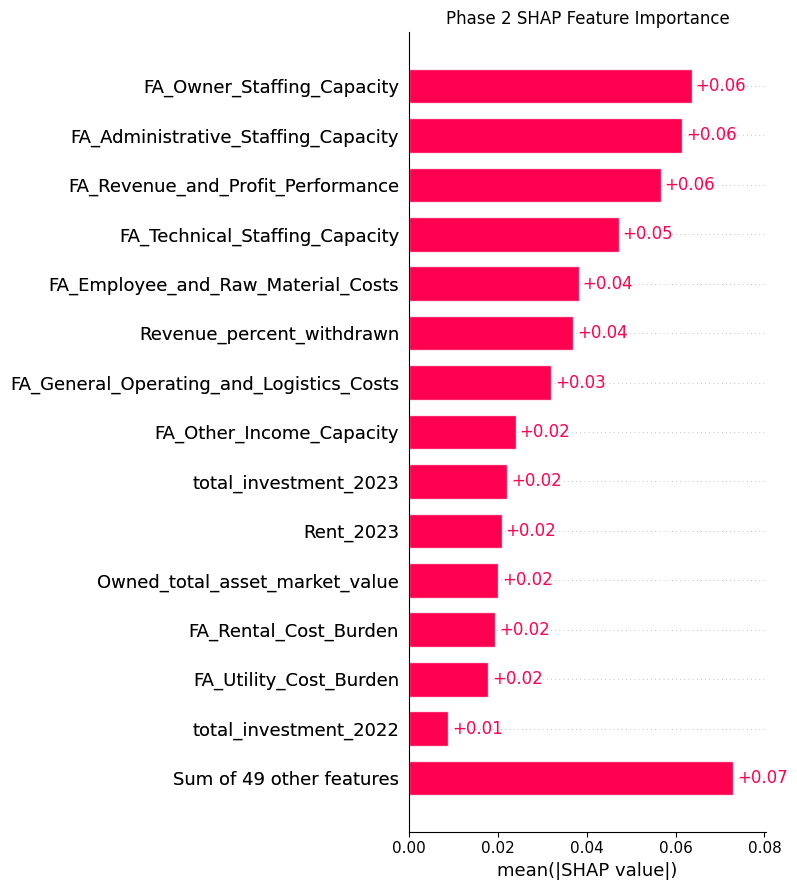

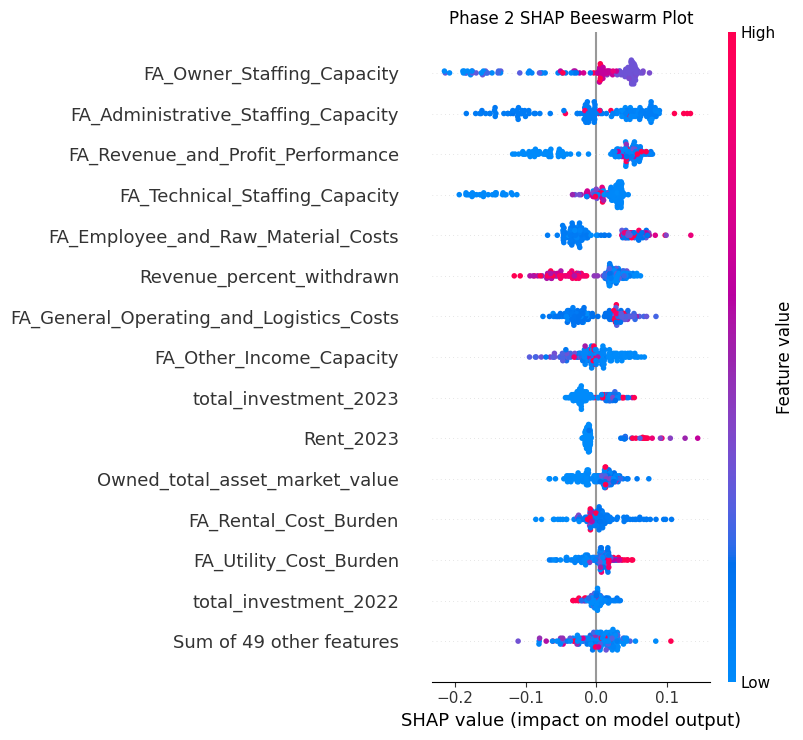

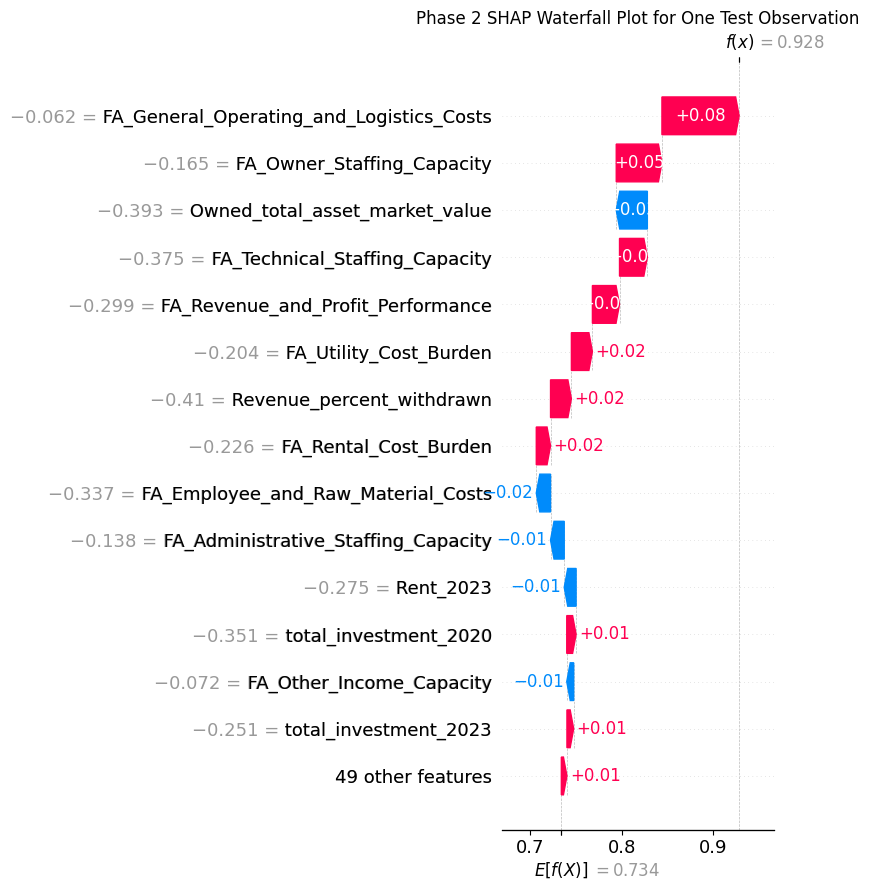

In [73]:
# ------------------------------------------------------------
# 3. Global SHAP importance table
# ------------------------------------------------------------

mean_abs_shap_df = pd.DataFrame({
    "feature": X2_explain.columns,
    "mean_abs_shap": np.abs(shap_values_2d.values).mean(axis=0)
}).sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)

display(mean_abs_shap_df.head(30))

mean_abs_shap_df.to_csv(
    shap_output_dir / "phase2_mean_abs_shap_importance.csv",
    index=False
)


# ------------------------------------------------------------
# 4. SHAP bar plot: overall feature importance
# ------------------------------------------------------------

shap.plots.bar(
    shap_values_2d,
    max_display=15,
    show=False
)

plt.title("Phase 2 SHAP Feature Importance")
plt.tight_layout()
plt.savefig(
    shap_output_dir / "phase2_shap_bar_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 5. SHAP beeswarm plot: direction and strength of effects
# ------------------------------------------------------------

shap.plots.beeswarm(
    shap_values_2d,
    max_display=15,
    show=False
)

plt.title("Phase 2 SHAP Beeswarm Plot")
plt.tight_layout()
plt.savefig(
    shap_output_dir / "phase2_shap_beeswarm_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 6. SHAP waterfall plot for one test observation
# ------------------------------------------------------------

row_to_explain = 0

shap.plots.waterfall(
    shap_values_2d[row_to_explain],
    max_display=15,
    show=False
)

plt.title("Phase 2 SHAP Waterfall Plot for One Test Observation")
plt.tight_layout()
plt.savefig(
    shap_output_dir / "phase2_shap_waterfall_row_0.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()